# 🏭 Lab 04b (Part 2 of 2): Production-Grade RAG System

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/varoonsahgal/adv-model-eval-student/blob/main/labs/04b-production-rag-part-2-lab.ipynb)

⏱️ ~25 min core (Tasks 9–11) · +55 min for the challenges

**Previously, in Part 1:**<br>
① Recall@5 tied; only evidence metrics told chunkers apart.<br>
② `recursive 200` won; headers cut failures, the reranker didn't.<br>
③ Now: generate, score, decide.

**How this lab works**
- ▶️ **Run**: <kbd>Shift</kbd>+<kbd>Enter</kbd>; collapsed 🧰 cells just need running.
- ✋ **Your turn**: replace the `...`; a card grades it.
- ❓ **Quick check**: pick an answer, then run.
- 🔑 **Key takeaway**: the line to remember.

▶️ **Run** the next five cells: 📦 install · imports · ⚙️ config · 🎨 lab kit · 🧰 catch-up (rebuilds Part 1).

In [ ]:
%%capture
# - sentence-transformers : local embeddings + optional cross-encoder reranker (no API key needed)
# - weaviate-client v4    : OPTIONAL embedded vector DB (only used if USE_WEAVIATE = True)
# - openai                : OPTIONAL, only used if PROVIDER = "openai"
!pip install -q sentence-transformers pandas numpy matplotlib "weaviate-client>=4.16,<5" openai

In [ ]:
# ============================================================
# IMPORTS
# ============================================================
import os, re, json, math
from typing import List, Dict, Optional
from dataclasses import dataclass
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer

pd.set_option("display.width", 160)
plt.rcParams["axes.axisbelow"] = True   # draw gridlines behind bars
print("✅ All imports successful!")

In [ ]:
# ============================================================
# LAB CONFIGURATION: the only cell you need to edit
# ============================================================
PROVIDER = "mock"            # "mock" (offline, default) | "openai" (needs OPENAI_API_KEY)
OPENAI_MODEL = "gpt-6-luna"  # OpenAI's named replacement for gpt-4o-mini (which shuts down 2027-01-14)
USE_WEAVIATE = False         # True = embedded Weaviate (downloads a ~150 MB server binary on first run)
RERANKER = "maxsim"          # "maxsim" (offline) | "cross-encoder" (downloads ~90 MB from Hugging Face)
K_CONTEXT = 3                # how many chunks the generator reads per question

if PROVIDER == "openai":
    OPENAI_API_KEY = os.environ.get("OPENAI_API_KEY", "")
    try:                                     # Colab: add the key under 🔑 Secrets
        from google.colab import userdata
        OPENAI_API_KEY = userdata.get("OPENAI_API_KEY") or OPENAI_API_KEY
    except Exception:
        pass
    if OPENAI_API_KEY:
        os.environ["OPENAI_API_KEY"] = OPENAI_API_KEY
    else:
        print("⚠️ PROVIDER='openai' but no OPENAI_API_KEY found: falling back to the mock generator.")
        PROVIDER = "mock"

print(f"⚙️  PROVIDER={PROVIDER} · vector store={'Weaviate (embedded)' if USE_WEAVIATE else 'in-memory'} "
      f"· reranker={RERANKER} · K_CONTEXT={K_CONTEXT}")

In [ ]:
# @title 🎨 Lab kit: insight cards, stat tiles, chart theme (run me; no need to read)
# LABKIT v2 — shared across every lab in this course. Pure Python + IPython; no installs.
# Functions you'll see used in this notebook:
#   insight(headline, body, kind="insight")   -> a callout card that states what the numbers just revealed
#   tiles([(label, value, note, status), ...])  -> a row of KPI tiles (status: good|warning|serious|critical|None)
#   verdict(decision, reasons)                  -> a SHIP / SHIP WITH CAUTION / BLOCK banner
#   style_charts()                              -> one consistent matplotlib theme (called automatically)
#   PALETTE / STATUS                            -> the colors used in every chart
#   check(label, got, expected, hint=, success=) -> grades a ✋ Your turn exercise: ✅ / ❌ + hint / ⏳ (still `...`)
#   quiz(label, choice, correct, why, wrong=)    -> grades a ❓ dropdown answer and explains it
#   todo(x)                                      -> True while an exercise blank is still `...`
#   scoreboard()                                 -> your exercise + quiz score so far, and what to revisit
import html as _html

try:
    from IPython.display import HTML as _HTML, display as _display
except ImportError:  # running as a plain script
    _HTML, _display = None, None

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
STATUS = {"good": "#0ca30c", "warning": "#fab219", "serious": "#ec835a", "critical": "#d03b3b"}
_STATUS_ICON = {"good": "✅", "warning": "⚠️", "serious": "🟠", "critical": "⛔"}

_KINDS = {
    #  kind        icon  label                    accent     tint
    "insight":    ("💡", "Insight",               "#2a78d6", "#eef5fd"),
    "surprise":   ("🤯", "Counterintuitive",      "#6250d6", "#f1effc"),
    "warning":    ("⚠️", "Watch out",             "#ec835a", "#fdf1ec"),
    "production": ("🏭", "In production",         "#1baf7a", "#ebf8f3"),
    "numbers":    ("📈", "By the numbers",        "#eda100", "#fdf6e6"),
    "research":   ("📚", "What the research says", "#52514e", "#f3f2ef"),
}


def _show(markup):
    if _display is not None:
        _display(_HTML(markup))
    else:
        import re
        print(re.sub(r"<[^>]+>", "", markup))


def _md(text):
    """Tiny formatter: **bold**, `code`, and newlines. Everything else is escaped."""
    import re
    t = _html.escape(str(text))
    t = re.sub(r"\*\*(.+?)\*\*", r"<b>\1</b>", t)
    t = re.sub(r"(?<![\w*])\*(?!\s)(.+?)(?<!\s)\*(?![\w*])", r"<i>\1</i>", t)
    t = re.sub(r"`(.+?)`", r"<code style='background:#0000000d;padding:1px 4px;border-radius:4px'>\1</code>", t)
    return t.replace("\n", "<br>")


def insight(headline, body="", kind="insight"):
    """Render a callout card. Use it right after a result to say what the result *means*."""
    icon, label, accent, tint = _KINDS.get(kind, _KINDS["insight"])
    _show(
        f"<div style='border-left:5px solid {accent};background:{tint};color:#0b0b0b;"
        f"padding:12px 16px;margin:10px 0;border-radius:8px;font-family:system-ui,-apple-system,sans-serif;"
        f"line-height:1.45;max-width:900px'>"
        f"<div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#52514e;"
        f"font-weight:600'>{icon} {label}</div>"
        f"<div style='font-size:16px;font-weight:650;margin:4px 0 6px'>{_md(headline)}</div>"
        f"<div style='font-size:14px;color:#2b2b2a'>{_md(body)}</div></div>"
    )


def tiles(items):
    """items: list of (label, value, note, status). status in good|warning|serious|critical|None."""
    cells = []
    for item in items:
        label, value, note, status = (list(item) + [None, None, None, None])[:4]
        color = STATUS.get(status, "#d9d8d4")
        icon = _STATUS_ICON.get(status, "")
        cells.append(
            f"<div style='flex:1 1 160px;min-width:150px;background:#fcfcfb;border:1px solid #e4e3df;"
            f"border-top:4px solid {color};border-radius:8px;padding:10px 14px'>"
            f"<div style='font-size:12px;color:#52514e'>{_md(label)}</div>"
            f"<div style='font-size:26px;font-weight:700;color:#0b0b0b;margin:2px 0'>{_md(value)}</div>"
            f"<div style='font-size:12px;color:#52514e'>{icon} {_md(note or '')}</div></div>"
        )
    _show(
        "<div style='display:flex;flex-wrap:wrap;gap:10px;margin:10px 0;"
        "font-family:system-ui,-apple-system,sans-serif;max-width:900px'>" + "".join(cells) + "</div>"
    )


def verdict(decision, reasons=()):
    """decision: 'SHIP' | 'SHIP WITH CAUTION' | 'BLOCK' (anything else renders neutral)."""
    d = str(decision).upper()
    status = "good" if d == "SHIP" else "critical" if d.startswith("BLOCK") else "warning"
    icon = {"good": "🚀", "critical": "🛑", "warning": "⚠️"}[status]
    items = "".join(f"<li>{_md(r)}</li>" for r in reasons)
    _show(
        f"<div style='border:2px solid {STATUS[status]};border-radius:10px;padding:12px 18px;margin:10px 0;"
        f"background:#fcfcfb;color:#0b0b0b;font-family:system-ui,-apple-system,sans-serif;max-width:900px'>"
        f"<div style='font-size:22px;font-weight:800'>{icon} {_html.escape(d)}</div>"
        f"<ul style='margin:6px 0 0 18px;padding:0;font-size:14px;line-height:1.5'>{items}</ul></div>"
    )


def style_charts():
    """One chart theme for the whole course: thin marks, recessive grid, fixed color order."""
    try:
        import matplotlib as mpl
        from cycler import cycler
    except ImportError:
        return
    mpl.rcParams.update({
        "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
        "axes.edgecolor": "#b9b8b3", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
        "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": "#e9e8e4", "grid.linewidth": 0.8,
        "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 11,
        "lines.linewidth": 2, "lines.markersize": 7, "legend.frameon": False,
        "axes.prop_cycle": cycler(color=PALETTE), "figure.dpi": 110,
    })


# ----------------------------------------------------------------- interactive: exercises, quizzes, score
_SCORE = {}   # label -> (kind, status) where status is "pass" | "fail" | "todo"


class _Graded(int):
    """check()/quiz() result: works like True/False (if, ==, sum) but prints nothing as a cell's last line."""
    def __repr__(self):
        return "True" if self else "False"

    def _ipython_display_(self):
        pass


def todo(x):
    """True while an exercise blank is still `...` (or None)."""
    return x is Ellipsis or x is None


def _card(icon, label, headline, body, accent, tint):
    _show(
        f"<div style='border-left:5px solid {accent};background:{tint};color:#0b0b0b;"
        f"padding:10px 16px;margin:8px 0;border-radius:8px;font-family:system-ui,-apple-system,sans-serif;"
        f"line-height:1.45;max-width:900px'>"
        f"<div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#52514e;"
        f"font-weight:600'>{icon} {_md(label)}</div>"
        f"<div style='font-size:16px;font-weight:650;margin:3px 0 4px'>{_md(headline)}</div>"
        f"<div style='font-size:14px;color:#2b2b2a'>{_md(body)}</div></div>"
    )


def _same(got, expected, tol):
    try:
        import numpy as _np
        if isinstance(got, (_np.generic,)):
            got = got.item()
        if isinstance(expected, (_np.generic,)):
            expected = expected.item()
    except ImportError:
        pass
    if isinstance(expected, bool) or isinstance(got, bool):
        return got == expected
    if isinstance(expected, (int, float)) and isinstance(got, (int, float)):
        return abs(float(got) - float(expected)) <= tol * max(1.0, abs(float(expected)))
    if isinstance(expected, str) and isinstance(got, str):
        return got.strip().lower() == expected.strip().lower()
    if isinstance(expected, (set, frozenset)) or isinstance(got, (set, frozenset)):
        try:
            return set(got) == set(expected)
        except TypeError:
            return False
    return got == expected


def check(label, got, expected=None, *, ok=None, tol=1e-6, hint="", success="", reveal=False):
    """Grade a ✋ Your turn exercise.

    got:      the learner's answer (still `...` = not attempted yet: shows ⏳, never an error)
    expected: the reference answer (compared with tolerance for numbers, case-insensitively for strings)
    ok:       pass a bool instead of `expected` for custom rules (e.g. ok=my_case_fools_the_grader)
    reveal:   show the expected answer on a wrong attempt (default False: the hint teaches, the answer spoils)
    """
    if todo(got):
        _SCORE[label] = ("exercise", "todo")
        _card("⏳", f"Your turn · {label}", "Not attempted yet",
              "Replace the `...` above with your answer and re-run this cell. "
              "The lab keeps going with the reference answer, so later cells still work.", "#9a9893", "#f3f2ef")
        return _Graded(False)
    try:
        passed = bool(ok) if ok is not None else _same(got, expected, tol)
    except Exception:
        passed = False
    _SCORE[label] = ("exercise", "pass" if passed else "fail")
    if passed:
        _card("✅", f"Correct · {label}", success or "Nice. That matches the reference.", "", "#0ca30c", "#ecf8ec")
    else:
        shown = f"You got `{got!r}`" + (f"; expected `{expected!r}`" if reveal and ok is None and expected is not None else "") + "."
        _card("❌", f"Not yet · {label}", shown, (f"💡 Hint: {hint}" if hint else "Re-read the step above and try again."),
              "#d03b3b", "#fcefef")
    return _Graded(passed)


def quiz(label, choice, correct, why, wrong=None):
    """Grade a ❓ dropdown answer. choice: the @param string, e.g. "B) The average hides it".
    correct: the letter ("B"). why: the explanation (shown once answered). wrong: {letter: feedback for that pick}."""
    pick = str(choice).strip()[:1].upper()
    if not pick.isalpha():
        _SCORE[label] = ("quiz", "todo")
        _card("❓", f"Quick check · {label}", "Pick an answer in the dropdown, then run this cell.",
              "Commit before you scroll: a guess you wrote down is what makes the next result stick.", "#9a9893", "#f3f2ef")
        return _Graded(False)
    passed = pick == str(correct).strip()[:1].upper()
    _SCORE[label] = ("quiz", "pass" if passed else "fail")
    extra = (wrong or {}).get(pick, "")
    if passed:
        _card("✅", f"Quick check · {label}", f"Right: {correct}.", why, "#0ca30c", "#ecf8ec")
    else:
        _card("🔁", f"Quick check · {label}", f"Not quite: you picked {pick}, the answer is {correct}.",
              (extra + "\n" if extra else "") + why, "#ec835a", "#fdf1ec")
    return _Graded(passed)


def scoreboard():
    """Your score on every ✋ exercise and ❓ quick check you've run, plus what to revisit."""
    ex = [s for k, s in _SCORE.values() if k == "exercise"]
    qz = [s for k, s in _SCORE.values() if k == "quiz"]
    redo = [lbl for lbl, (_, s) in _SCORE.items() if s != "pass"]
    tiles([
        ("✋ Exercises solved", f"{ex.count('pass')}/{len(ex)}", f"{ex.count('todo')} not attempted",
         "good" if ex and ex.count("pass") == len(ex) else "warning"),
        ("❓ Quick checks right", f"{qz.count('pass')}/{len(qz)}", f"{qz.count('todo')} unanswered",
         "good" if qz and qz.count("pass") == len(qz) else "warning"),
    ])
    if redo:
        insight("Worth a second pass", "\n".join(f"• {r}" for r in redo), kind="warning")
    elif _SCORE:
        insight("Clean sweep", "Every exercise and quick check correct. Try the 🏆 challenges next.", kind="insight")


style_charts()
print("🎨 Lab kit loaded: insight(), tiles(), verdict(), check(), quiz(), scoreboard()")

In [ ]:
# @title 🧰 Catch-up: rebuild what Part 1 computed (hidden · 1169 lines)
import io as _io, sys as _sys
_real_out, _real_err = _sys.stdout, _sys.stderr
_sys.stdout = _sys.stderr = _io.StringIO()

# ── from Part 1 (cell 10) ────────────────────────────────────────
# ============================================================
# SAMPLE DOCUMENT CORPUS: docs for "BrookPipe", a FICTIONAL data-pipeline product
# ============================================================
# ⚠️ BrookPipe doesn't exist. Commands inside these docs (`pip install brookpipe`,
#    `brookpipe dashboard`, ...) are part of the fake corpus: don't run them.
#
# Each document has: id, title, category, content (markdown).
# Docs 001–006 are the product guides. Doc 007 (a 1.x → 2.0 migration guide) and
# doc 008 (FAQ + error codes) are realistic *distractors*: they mention configuration,
# retries, auth and alerts too, but usually aren't the best answer.
#
# In production you'd load docs from S3/GCS, a CMS, a wiki export or a docs repo.

DOCUMENTS = [
    {
        "id": "doc-001",
        "title": "Getting Started with BrookPipe",
        "category": "quickstart",
        "content": """
# Getting Started with BrookPipe

BrookPipe is a modern data pipeline orchestration platform that helps you build, deploy, and monitor data workflows at scale.

## Installation

Install BrookPipe using pip:

```bash
pip install brookpipe
```

## Quick Start

Create your first pipeline in 3 steps:

1. **Define your pipeline** using Python decorators
2. **Configure sources and sinks** in YAML
3. **Deploy to BrookPipe Cloud** with one command

Example pipeline:

```python
from brookpipe import Pipeline, task

@task
def extract_data():
    return fetch_from_api()

@task
def transform_data(raw_data):
    return clean_and_validate(raw_data)

@task  
def load_data(clean_data):
    write_to_database(clean_data)

pipeline = Pipeline([extract_data, transform_data, load_data])
```

## Key Concepts

- **Pipeline**: A directed acyclic graph (DAG) of tasks
- **Task**: A single unit of work (Python function)
- **Trigger**: What starts a pipeline (schedule, event, API call)
- **Run**: A single execution of a pipeline

## Next Steps

- Read the Configuration Guide for advanced options
- Check out the Monitoring Guide to track your pipelines
- Join our Slack community for help
"""
    },
    {
        "id": "doc-002", 
        "title": "BrookPipe Configuration Guide",
        "category": "configuration",
        "content": """
# Configuration Guide

BrookPipe uses YAML configuration files to define pipeline settings, connections, and deployment options.

## Configuration File Location

BrookPipe looks for configuration in this order:
1. `./brookpipe.yaml` (current directory)
2. `~/.brookpipe/config.yaml` (user home)
3. `/etc/brookpipe/config.yaml` (system-wide)

## Basic Configuration

```yaml
# brookpipe.yaml
version: "2.0"

project:
  name: my-data-pipeline
  environment: production

connections:
  postgres:
    type: postgresql
    host: ${POSTGRES_HOST}
    port: 5432
    database: analytics
    credentials:
      secret: postgres-credentials

  s3:
    type: s3
    bucket: my-data-bucket
    region: us-west-2
```

## Environment Variables

Use `${VAR_NAME}` syntax to reference environment variables. This is the recommended way to handle secrets.

## Connection Types

BrookPipe supports these connection types:
- **postgresql**: PostgreSQL databases
- **mysql**: MySQL databases
- **s3**: Amazon S3 buckets
- **gcs**: Google Cloud Storage
- **kafka**: Apache Kafka topics
- **http**: REST APIs

## Pipeline-Specific Configuration

Each pipeline can override global settings:

```yaml
pipelines:
  daily-etl:
    schedule: "0 6 * * *"  # 6 AM daily
    timeout: 3600  # 1 hour
    retries: 3
    notifications:
      on_failure: slack-alerts
```

## Secrets Management

Never put secrets directly in config files. Use:
1. Environment variables
2. BrookPipe Secrets Manager
3. External secret managers (Vault, AWS Secrets Manager)
"""
    },
    {
        "id": "doc-003",
        "title": "BrookPipe Monitoring and Observability",
        "category": "monitoring",
        "content": """
# Monitoring and Observability

BrookPipe provides comprehensive monitoring capabilities to help you track pipeline health, debug issues, and optimize performance.

## Built-in Metrics

Every pipeline automatically tracks:
- **Run duration**: How long each run takes
- **Success/failure rate**: Percentage of successful runs
- **Task latency**: Time spent in each task
- **Data volume**: Rows processed, bytes transferred
- **Resource usage**: CPU, memory, network

## Dashboard

Access the monitoring dashboard at `https://app.brookpipe.example/monitoring` or run locally:

```bash
brookpipe dashboard
```

## Alerts

Configure alerts for pipeline issues:

```yaml
alerts:
  pipeline-failure:
    condition: run.status == "failed"
    channels: [slack, pagerduty]
    
  slow-pipeline:
    condition: run.duration > 2 * run.average_duration
    channels: [slack]
    
  data-quality:
    condition: metrics.null_rate > 0.05
    channels: [email]
```

## Logging

Logs are structured JSON by default. Configure log levels per task:

```python
@task(log_level="DEBUG")
def my_task():
    logger.info("Processing started", extra={"batch_id": 123})
```

## Integration with External Tools

BrookPipe integrates with:
- **Prometheus**: Metrics export
- **Grafana**: Dashboard templates
- **Datadog**: Full APM integration
- **PagerDuty**: Incident routing
- **Slack**: Notifications

## Debugging Failed Runs

When a run fails:
1. Check the run logs in the dashboard
2. Look at the failed task's stack trace
3. Review input data for that task
4. Use `brookpipe run --rerun-failed` to retry just failed tasks
"""
    },
    {
        "id": "doc-004",
        "title": "BrookPipe Error Handling",
        "category": "troubleshooting",
        "content": """
# Error Handling

BrookPipe provides robust error handling to ensure reliable pipeline execution.

## Retry Configuration

Configure retries at the task level:

```python
@task(retries=3, retry_delay=60)  # Retry 3 times, wait 60s between
def flaky_api_call():
    return requests.get(api_url).json()
```

Or at the pipeline level in YAML:

```yaml
pipelines:
  my-pipeline:
    retries: 3
    retry_delay: 60
    retry_backoff: exponential  # 60s, 120s, 240s
```

## Error Types

BrookPipe distinguishes between:
- **Transient errors**: Network timeouts, rate limits (auto-retry)
- **Data errors**: Invalid input data (requires fix)
- **Code errors**: Bugs in task code (requires code change)

## Dead Letter Queues

For streaming pipelines, configure DLQ to capture failed messages:

```yaml
pipelines:
  streaming-etl:
    dead_letter_queue:
      type: kafka
      topic: failed-messages
      retention: 7d
```

## Circuit Breakers

Prevent cascading failures with circuit breakers:

```python
@task(circuit_breaker={"failures": 5, "timeout": 300})
def external_api_task():
    # If this fails 5 times in 5 minutes, circuit opens
    return call_external_api()
```

## Handling Partial Failures

For batch processing, handle partial failures:

```python
@task(on_partial_failure="continue")  # Don't fail entire batch
def process_batch(records):
    results = []
    for record in records:
        try:
            results.append(process(record))
        except Exception as e:
            logger.error(f"Failed to process {record.id}", exc_info=e)
            results.append(ErrorRecord(record.id, str(e)))
    return results
```
"""
    },
    {
        "id": "doc-005",
        "title": "BrookPipe Security Best Practices",
        "category": "security",
        "content": """
# Security Best Practices

Follow these guidelines to secure your BrookPipe deployments.

## Authentication

BrookPipe supports multiple authentication methods:
- **API Keys**: For programmatic access
- **OAuth 2.0**: For user authentication
- **SAML**: For enterprise SSO

Never hardcode credentials. Use:

```python
# Bad - hardcoded credentials
conn = connect(password="secret123")

# Good - environment variable
conn = connect(password=os.environ["DB_PASSWORD"])

# Better - secrets manager
conn = connect(password=secrets.get("db-password"))
```

## Network Security

- Use VPC peering for database connections
- Enable TLS for all external connections
- Use private endpoints where available

## Data Encryption

BrookPipe encrypts data:
- **At rest**: AES-256 encryption
- **In transit**: TLS 1.3
- **In memory**: Secure memory handling

For sensitive data, enable column-level encryption:

```yaml
pipelines:
  pii-pipeline:
    encryption:
      columns: [ssn, credit_card, email]
      algorithm: AES-256-GCM
      key_id: pii-encryption-key
```

## Access Control

Use role-based access control (RBAC):

```yaml
roles:
  developer:
    - pipelines:read
    - pipelines:write
    - runs:read
    
  operator:
    - pipelines:read
    - runs:read
    - runs:trigger
    
  admin:
    - "*:*"
```

## Audit Logging

All actions are logged for compliance:
- Who did what
- When it happened  
- What data was accessed
- What changed
"""
    },
    {
        "id": "doc-006",
        "title": "BrookPipe Performance Optimization",
        "category": "performance",
        "content": """
# Performance Optimization

Optimize your BrookPipe pipelines for speed and efficiency.

## Parallelization

Run independent tasks in parallel:

```python
# These run in parallel automatically
@task
def extract_users():
    return fetch_users()

@task
def extract_orders():
    return fetch_orders()

@task
def join_data(users, orders):  # Waits for both
    return merge(users, orders)
```

## Batch Processing

Process data in batches to reduce overhead:

```python
@task(batch_size=1000)
def process_records(records):
    # Process 1000 records at a time
    return bulk_insert(records)
```

## Caching

Cache expensive computations:

```python
@task(cache_key="{date}", cache_ttl=3600)
def fetch_daily_data(date):
    # Cached for 1 hour per date
    return expensive_api_call(date)
```

## Resource Allocation

Allocate resources based on task needs:

```yaml
tasks:
  heavy-computation:
    resources:
      cpu: 4
      memory: 16GB
      gpu: 1
      
  light-task:
    resources:
      cpu: 0.5
      memory: 512MB
```

## Common Bottlenecks

1. **Database connections**: Use connection pooling
2. **API rate limits**: Implement backoff strategies
3. **Memory pressure**: Stream large datasets
4. **Network latency**: Co-locate with data sources
"""
    },
    {
        "id": "doc-007",
        "title": "Migrating from BrookPipe 1.x to 2.0",
        "category": "migration",
        "content": """
# Migrating from BrookPipe 1.x to 2.0

BrookPipe 2.0 changes several defaults. Read this guide before upgrading production pipelines.

## Configuration changes

In 1.x, configuration lived in a single `~/.brookpipe.yml` file. In 2.0 the search order changed; see the Configuration Guide. The `version` key must now be `"2.0"`.

## Retry syntax

The 1.x decorator `@task(max_retries=5)` is deprecated. Use `retries` and `retry_delay` instead. Pipeline-level retries in YAML are unchanged.

## Authentication

1.x supported API keys only. 2.0 adds OAuth 2.0 and SAML single sign-on. Existing API keys keep working.

## Monitoring and alerts

The 1.x `brookpipe status` command is replaced by the monitoring dashboard. Alert rules written for 1.x must be rewritten with the new `condition:` syntax.

## Removed features

- The `--legacy-scheduler` flag
- Python 3.8 support
- The built-in FTP connection type
"""
    },
    {
        "id": "doc-008",
        "title": "BrookPipe FAQ and Error Codes",
        "category": "faq",
        "content": """
# FAQ and Error Codes

## Does BrookPipe run on Windows?

Yes, through WSL 2. Native Windows support is planned.

## Why is my pipeline slower than expected?

The most common causes are missing connection pooling and unbatched writes. See the Performance Optimization guide.

## Can two pipelines share a task?

Yes. Import the task function into both pipeline definitions.

## Error codes

- **BP-1001**: configuration file not found. Check the search order in the Configuration Guide.
- **BP-2210**: connection refused by a source or sink. Check credentials and network rules.
- **BP-4031**: a task exceeded its `timeout`. Increase the timeout or split the task.
- **BP-5002**: the circuit breaker is open for this task. Wait for the breaker timeout or fix the upstream service.
"""
    }
]

print(f"✅ Created {len(DOCUMENTS)} documents for the RAG corpus")
print(f"   Categories: {set(d['category'] for d in DOCUMENTS)}")
print(f"   Total content: {sum(len(d['content']) for d in DOCUMENTS):,} characters")

# ── from Part 1 (cell 11) ────────────────────────────────────────
# ============================================================
# EVALUATION DATASET WITH GROUND TRUTH
# ============================================================
# For each question we store:
#   - ground_truth_answer : what a correct answer says
#   - relevant_doc_ids    : which documents contain the answer (for document-level metrics)
#   - evidence            : the EXACT text span(s) that answer it (for token-level metrics, Task 6)
#   - style               : "keyword" (exact identifiers), "paraphrase" (no doc vocabulary) or "standard"
#
# In production these come from user query logs, support tickets and SME annotation.

EVALUATION_DATASET = [
    {"question": "How do I install BrookPipe?",
     "ground_truth_answer": "Install BrookPipe using pip: pip install brookpipe",
     "relevant_doc_ids": ["doc-001"], "category": "installation", "style": "standard",
     "evidence": ["Install BrookPipe using pip:\n\n```bash\npip install brookpipe\n```"]},
    {"question": "Where does BrookPipe look for configuration files?",
     "ground_truth_answer": "In this order: ./brookpipe.yaml, ~/.brookpipe/config.yaml, /etc/brookpipe/config.yaml",
     "relevant_doc_ids": ["doc-002"], "category": "configuration", "style": "standard",
     "evidence": ["BrookPipe looks for configuration in this order:\n1. `./brookpipe.yaml` (current directory)\n2. `~/.brookpipe/config.yaml` (user home)\n3. `/etc/brookpipe/config.yaml` (system-wide)"]},
    {"question": "How can I monitor my pipeline's performance?",
     "ground_truth_answer": "BrookPipe tracks run duration, success/failure rate, task latency, data volume and resource usage; see the monitoring dashboard.",
     "relevant_doc_ids": ["doc-003"], "category": "monitoring", "style": "standard",
     "evidence": ["Every pipeline automatically tracks:\n- **Run duration**: How long each run takes\n- **Success/failure rate**: Percentage of successful runs\n- **Task latency**: Time spent in each task\n- **Data volume**: Rows processed, bytes transferred\n- **Resource usage**: CPU, memory, network"]},
    {"question": "How do I configure retries for failed tasks?",
     "ground_truth_answer": "At task level with @task(retries=3, retry_delay=60), or at pipeline level in YAML.",
     "relevant_doc_ids": ["doc-004"], "category": "troubleshooting", "style": "standard",
     "evidence": ["@task(retries=3, retry_delay=60)  # Retry 3 times, wait 60s between"]},
    {"question": "What authentication methods does BrookPipe support?",
     "ground_truth_answer": "API keys, OAuth 2.0 and SAML for enterprise SSO.",
     "relevant_doc_ids": ["doc-005"], "category": "security", "style": "standard",
     "evidence": ["- **API Keys**: For programmatic access\n- **OAuth 2.0**: For user authentication\n- **SAML**: For enterprise SSO"]},
    {"question": "How can I run tasks in parallel?",
     "ground_truth_answer": "Independent tasks run in parallel automatically.",
     "relevant_doc_ids": ["doc-006"], "category": "performance", "style": "standard",
     "evidence": ["Run independent tasks in parallel:"]},
    {"question": "How do I handle sensitive data like passwords?",
     "ground_truth_answer": "Never hardcode credentials; use environment variables or a secrets manager. Data is encrypted at rest with AES-256.",
     "relevant_doc_ids": ["doc-002", "doc-005"], "category": "security", "style": "standard",
     "evidence": ["Never put secrets directly in config files.", "Never hardcode credentials."]},
    {"question": "What is a Pipeline in BrookPipe?",
     "ground_truth_answer": "A Pipeline is a directed acyclic graph (DAG) of tasks.",
     "relevant_doc_ids": ["doc-001"], "category": "concepts", "style": "standard",
     "evidence": ["- **Pipeline**: A directed acyclic graph (DAG) of tasks"]},
    {"question": "How do I set up alerts for pipeline failures?",
     "ground_truth_answer": "Configure alerts in YAML with a condition such as run.status == \"failed\" and channels such as slack and pagerduty.",
     "relevant_doc_ids": ["doc-003"], "category": "monitoring", "style": "standard",
     "evidence": ["  pipeline-failure:\n    condition: run.status == \"failed\"\n    channels: [slack, pagerduty]"]},
    {"question": "What databases can BrookPipe connect to?",
     "ground_truth_answer": "PostgreSQL and MySQL (plus S3, GCS, Kafka and HTTP connections).",
     "relevant_doc_ids": ["doc-002"], "category": "configuration", "style": "standard",
     "evidence": ["- **postgresql**: PostgreSQL databases\n- **mysql**: MySQL databases"]},
    # --- exact identifiers: the kind of query keyword search is good at ---
    {"question": "What does error BP-4031 mean?",
     "ground_truth_answer": "A task exceeded its timeout; increase the timeout or split the task.",
     "relevant_doc_ids": ["doc-008"], "category": "troubleshooting", "style": "keyword",
     "evidence": ["**BP-4031**: a task exceeded its `timeout`. Increase the timeout or split the task."]},
    {"question": "What does --rerun-failed do?",
     "ground_truth_answer": "`brookpipe run --rerun-failed` retries just the failed tasks of a run.",
     "relevant_doc_ids": ["doc-003"], "category": "troubleshooting", "style": "keyword",
     "evidence": ["Use `brookpipe run --rerun-failed` to retry just failed tasks"]},
    # --- paraphrases: users don't use the docs' vocabulary ---
    {"question": "How do I stop one flaky third-party service from taking down everything downstream?",
     "ground_truth_answer": "Wrap the call in a circuit breaker, e.g. @task(circuit_breaker={\"failures\": 5, \"timeout\": 300}).",
     "relevant_doc_ids": ["doc-004"], "category": "troubleshooting", "style": "paraphrase",
     "evidence": ["Prevent cascading failures with circuit breakers:"]},
    {"question": "How are social security numbers protected in my tables?",
     "ground_truth_answer": "Enable column-level encryption (AES-256-GCM) for sensitive columns such as ssn.",
     "relevant_doc_ids": ["doc-005"], "category": "security", "style": "paraphrase",
     "evidence": ["For sensitive data, enable column-level encryption:"]},
]

# ── from Part 1 (cell 12) ────────────────────────────────────────
# Locate every evidence span inside its document (character offsets). A span we can't find is a
# labeling bug, so fail loudly: evaluation data deserves the same tests as code.
DOC_TEXT = {d["id"]: d["content"].strip() for d in DOCUMENTS}
for item in EVALUATION_DATASET:
    spans = []
    for ev in item["evidence"]:
        hits = [(doc_id, text.find(ev)) for doc_id, text in DOC_TEXT.items()
                if doc_id in item["relevant_doc_ids"] and ev in text]
        # 👀 Look at: a label that no longer matches its document fails the build, not the metric
        assert hits, f"evidence not found for: {item['question']!r}"
        doc_id, start = hits[0]
        spans.append((doc_id, start, start + len(ev)))
    item["evidence_spans"] = spans

print(f"✅ Created {len(EVALUATION_DATASET)} evaluation questions with ground truth and evidence spans")
print(f"   Styles: {dict(Counter(q['style'] for q in EVALUATION_DATASET))}")

# ── from Part 1 (cell 15) ────────────────────────────────────────
# Sizes are in TOKENS, estimated as characters / 4 (OpenAI's rule of thumb for English).
# Every chunk stores start/end character offsets into its document, so Task 6 can measure
# exactly how much answer-bearing text each chunk covers.

CHARS_PER_TOKEN = 4

@dataclass
class Chunk:
    """A single chunk: its text plus where it came from (doc + character span)."""
    id: str
    content: str
    doc_id: str
    doc_title: str
    chunk_index: int
    start_char: int
    end_char: int


def _make_chunks(doc, spans):
    text = DOC_TEXT[doc["id"]]
    return [Chunk(id=f"{doc['id']}_chunk_{i:03d}", content=text[s:e], doc_id=doc["id"],
                  doc_title=doc["title"], chunk_index=i, start_char=s, end_char=e)
            for i, (s, e) in enumerate(spans) if text[s:e].strip()]


def _split_points(text, start, end, sep):
    """Offsets where a piece may start: just after each separator inside [start, end)."""
    points, i = [start], text.find(sep, start)
    while 0 <= i < end:
        cut = i + len(sep) if sep.strip() in (".",) else i + 1   # keep headers with their section
        if start < cut < end:
            points.append(cut)
        i = text.find(sep, i + len(sep))
    return points + [end]


def _recursive_spans(text, start, end, max_chars, seps):
    if end - start <= max_chars:
        return [(start, end)]
    for k, sep in enumerate(seps):
        points = _split_points(text, start, end, sep)
        if len(points) <= 2:
            continue                                    # this separator doesn't occur here; try a finer one
        spans, cur = [], points[0]
        for a, b in zip(points[:-1], points[1:]):       # greedily pack pieces up to max_chars
            if b - cur > max_chars and a > cur:
                spans.append((cur, a)); cur = a
        spans.append((cur, end))
        out = []
        for s, e in spans:                              # pieces that are still too big: recurse finer
            out += _recursive_spans(text, s, e, max_chars, seps[k + 1:]) if e - s > max_chars else [(s, e)]
        return out
    return [(s, min(s + max_chars, end)) for s in range(start, end, max_chars)]   # last resort: hard cut


def recursive_chunking(documents, chunk_tokens=200):
    """Recursive splitting (the idea behind LangChain's RecursiveCharacterTextSplitter):
    try section breaks first, then paragraphs, then lines, then sentences, then words,
    and only cut finer when a piece is still too big. No overlap."""
    seps = ["\n## ", "\n\n", "\n", ". ", " "]
    chunks = []
    for doc in documents:
        text = DOC_TEXT[doc["id"]]
        chunks += _make_chunks(doc, _recursive_spans(text, 0, len(text), chunk_tokens * CHARS_PER_TOKEN, seps))
    return chunks


def semantic_chunking(documents, max_tokens=200):
    """Structure-aware: one chunk per markdown section (## heading), split further only
    if a section is longer than max_tokens."""
    chunks = []
    for doc in documents:
        text = DOC_TEXT[doc["id"]]
        sections = _split_points(text, 0, len(text), "\n## ")
        spans = []
        for s, e in zip(sections[:-1], sections[1:]):
            spans += _recursive_spans(text, s, e, max_tokens * CHARS_PER_TOKEN, ["\n\n", "\n", ". ", " "])
        chunks += _make_chunks(doc, spans)
    return chunks


def describe(chunks):
    lens = [len(c.content) // CHARS_PER_TOKEN for c in chunks]
    return f"{len(chunks):3d} chunks, ~{np.mean(lens):.0f} tokens avg (min {min(lens)}, max {max(lens)})"

# ── from Part 1 (cell 16) ────────────────────────────────────────
# ============================================================
# CHUNKING: the fixed-size window (recursive and semantic chunkers are in the hidden cell above)
# ============================================================
def fixed_size_chunking(documents, chunk_tokens=125, overlap_tokens=12):
    """Slide a fixed window across each document. Simple and predictable, but it cuts
    mid-sentence and mid-code-block. (Defaults ≈ 500 / 50 characters.)"""
    # 👀 Look at: the window advances by (size − overlap), so neighbours share `overlap_tokens` tokens
    size, step = chunk_tokens * CHARS_PER_TOKEN, (chunk_tokens - overlap_tokens) * CHARS_PER_TOKEN
    chunks = []
    for doc in documents:
        n = len(DOC_TEXT[doc["id"]])
        spans = [(s, min(s + size, n)) for s in range(0, n, step)]
        spans = [sp for i, sp in enumerate(spans) if i == 0 or sp[1] > spans[i - 1][1]]  # drop pure-overlap tails
        chunks += _make_chunks(doc, spans)
    return chunks


fixed_chunks = fixed_size_chunking(DOCUMENTS)          # ≈ 500 chars, 50 overlap: a classic tutorial default
semantic_chunks = semantic_chunking(DOCUMENTS)         # one chunk per section
print("✅ Created chunks using two strategies:")
print(f"   Fixed-size (125 tok, 12 overlap): {describe(fixed_chunks)}")
print(f"   Semantic (by section):            {describe(semantic_chunks)}")

# ── from Part 1 (cell 20) ────────────────────────────────────────
# ============================================================
# THE VECTOR STORE: one tiny interface, two backends
# ============================================================
# Every database call goes through: recreate(name) · insert(name, objects, vectors) · count(name)
#                                   · search(name, query_text, query_vector, k, mode)
# mode = "dense" (vector similarity) | "bm25" (keyword) | "hybrid" (both, fused with RRF)
#
# The two backends behind that interface (in-memory numpy + BM25, optional embedded Weaviate) are in the
# hidden cell below; this cell holds the two ideas they share: BM25's tokenizer and rank fusion.

TOKEN_RE = re.compile(r"[a-z0-9]+(?:[-_.][a-z0-9]+)*")

def bm25_tokens(text):
    """Lowercase word tokens that keep identifiers like 'bp-4031' and 'rerun-failed' intact."""
    return TOKEN_RE.findall(text.lower())


def rrf_fuse(rankings, k=60):
    """Reciprocal Rank Fusion: score(item) = Σ 1 / (k + rank). Uses ranks only, so the
    incompatible score scales of BM25 and cosine similarity don't matter."""
    scores = defaultdict(float)
    for ranking in rankings:
        for rank, idx in enumerate(ranking, start=1):
            # 👀 Look at: only the RANK enters the score; BM25's 0–20 and cosine's 0–1 never meet
            scores[idx] += 1.0 / (k + rank)
    return sorted(scores, key=lambda i: -scores[i])

# ── from Part 1 (cell 21) ────────────────────────────────────────
class InMemoryStore:
    """Brute-force cosine search + Okapi BM25 in numpy. Fine up to ~100k chunks."""
    backend = "in-memory (numpy + BM25)"

    def __init__(self):
        self.cols = {}

    def recreate(self, name):
        self.cols[name] = {"objects": [], "vectors": None, "tokens": []}

    def insert(self, name, objects, vectors):
        col = self.cols[name]
        v = np.asarray(vectors, dtype=float)
        v = v / np.linalg.norm(v, axis=1, keepdims=True)
        col["objects"] += list(objects)
        col["vectors"] = v if col["vectors"] is None else np.vstack([col["vectors"], v])
        col["tokens"] += [bm25_tokens(o.get("search_text", o["content"])) for o in objects]
        toks = col["tokens"]                                   # refresh BM25 statistics
        col["df"] = Counter(t for doc in toks for t in set(doc))
        col["avgdl"] = np.mean([len(d) for d in toks])

    def count(self, name):
        return len(self.cols[name]["objects"])

    def _bm25(self, col, query, k1=1.5, b=0.75):
        n = len(col["tokens"])
        q = bm25_tokens(query)
        scores = np.zeros(n)
        for i, doc in enumerate(col["tokens"]):
            tf = Counter(doc)
            for t in q:
                if t in tf:
                    idf = np.log(1 + (n - col["df"][t] + 0.5) / (col["df"][t] + 0.5))
                    scores[i] += idf * tf[t] * (k1 + 1) / (tf[t] + k1 * (1 - b + b * len(doc) / col["avgdl"]))
        return scores

    def search(self, name, query_text, query_vector, k, mode="dense"):
        col = self.cols[name]
        q = np.asarray(query_vector, dtype=float); q = q / np.linalg.norm(q)
        sims = col["vectors"] @ q
        dense_rank = list(np.argsort(-sims))
        if mode == "dense":
            order = dense_rank
        elif mode == "bm25":
            bm = self._bm25(col, query_text)
            order = list(np.argsort(-bm, kind="stable"))
        elif mode == "hybrid":
            bm = self._bm25(col, query_text)
            order = rrf_fuse([dense_rank, list(np.argsort(-bm, kind="stable"))])
        else:
            raise ValueError(mode)
        return [{"id": f"{name}-{i}", "score": float(sims[i]), **col["objects"][i]} for i in order[:k]]

    def close(self):
        pass


class WeaviateStore:
    """Embedded Weaviate (v4 client). Downloads a ~150 MB server binary on first use."""
    backend = "weaviate-embedded"

    def __init__(self):
        import tempfile, weaviate
        self.wv = weaviate
        self.client = weaviate.connect_to_embedded(
            persistence_data_path=os.path.join(tempfile.gettempdir(), "weaviate-lab04b"),
            environment_variables={"LOG_LEVEL": "error",
                                   # Weaviate turns read-only when the disk is >90% full. Laptops often are.
                                   "DISK_USE_READONLY_PERCENTAGE": "100", "DISK_USE_WARNING_PERCENTAGE": "100"})

    def recreate(self, name):
        from weaviate.classes.config import Configure, Property, DataType
        if self.client.collections.exists(name):
            self.client.collections.delete(name)
        props = [Property(name=p, data_type=DataType.TEXT) for p in ("content", "search_text", "doc_id", "doc_title", "chunk_id")]
        props += [Property(name=p, data_type=DataType.INT) for p in ("chunk_index", "start_char", "end_char")]
        self.client.collections.create(name, properties=props, vector_config=Configure.Vectors.self_provided())

    def insert(self, name, objects, vectors):
        col = self.client.collections.get(name)
        with col.batch.fixed_size(batch_size=100) as batch:
            for obj, vec in zip(objects, vectors):
                batch.add_object(properties={"search_text": obj["content"], **obj}, vector=[float(x) for x in vec])
        if col.batch.failed_objects:
            raise RuntimeError(f"{len(col.batch.failed_objects)} objects failed: {col.batch.failed_objects[0].message}")

    def count(self, name):
        return self.client.collections.get(name).aggregate.over_all(total_count=True).total_count

    def search(self, name, query_text, query_vector, k, mode="dense"):
        from weaviate.classes.query import MetadataQuery, HybridFusion
        col, vec = self.client.collections.get(name), [float(x) for x in query_vector]
        md = MetadataQuery(distance=True, score=True)
        if mode == "dense":
            res = col.query.near_vector(near_vector=vec, limit=k, return_metadata=md)
        elif mode == "bm25":
            res = col.query.bm25(query=query_text, query_properties=["search_text"], limit=k, return_metadata=md)
        else:   # Weaviate's native hybrid, with rank-based fusion (same idea as rrf_fuse)
            res = col.query.hybrid(query=query_text, vector=vec, alpha=0.5, query_properties=["search_text"],
                                   fusion_type=HybridFusion.RANKED, limit=k, return_metadata=md)
        out = []
        for o in res.objects:
            d = o.metadata.distance
            out.append({"id": str(o.uuid), "score": 1 - d if d is not None else float(o.metadata.score or 0), **o.properties})
        return out

    def close(self):
        self.client.close()


def make_store():
    if USE_WEAVIATE:
        try:
            s = WeaviateStore()
            print(f"✅ Embedded Weaviate is ready: {s.client.is_ready()}")
            return s
        except Exception as e:
            print(f"⚠️  Embedded Weaviate unavailable ({type(e).__name__}: {str(e)[:120]})")
            print("   Falling back to the in-memory store. Every later cell works the same way.")
    return InMemoryStore()


store = make_store()
print(f"🗄️  Vector store backend: {store.backend}")

# ── from Part 1 (cell 22) ────────────────────────────────────────
# ============================================================
# EMBEDDING MODEL
# ============================================================
# all-MiniLM-L6-v2: small (384-dim), fast on CPU, free, still the sentence-transformers showcase model.
# In production you'd compare it against an API model (e.g. OpenAI text-embedding-3-small) on YOUR eval set.
# If the model can't be downloaded (no internet), we fall back to a TF-IDF + SVD embedder so every
# later cell still runs; the numbers will differ from the Expected Output blocks.
try:
    embedding_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
    EMBEDDER = "all-MiniLM-L6-v2"

    def embed_texts(texts):
        # 👀 Look at: normalized vectors, so a dot product IS cosine similarity
        return embedding_model.encode(list(texts), show_progress_bar=False, normalize_embeddings=True)
except Exception as e:
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.decomposition import TruncatedSVD
    print(f"⚠️ Could not load MiniLM ({type(e).__name__}); using a TF-IDF + SVD fallback embedder.")
    _paras = [p for d in DOCUMENTS for p in d["content"].split("\n\n") if p.strip()]
    _tfidf = TfidfVectorizer(sublinear_tf=True).fit(_paras)
    _svd = TruncatedSVD(n_components=48, random_state=0).fit(_tfidf.transform(_paras))
    EMBEDDER = "tfidf-svd (fallback)"

    def embed_texts(texts):
        v = _svd.transform(_tfidf.transform(list(texts)))
        return v / (np.linalg.norm(v, axis=1, keepdims=True) + 1e-9)

EMBEDDING_DIM = embed_texts(["probe"]).shape[1]
print(f"✅ Embedding model: {EMBEDDER} ({EMBEDDING_DIM}-dim)")

# ── from Part 1 (cell 24) ────────────────────────────────────────
# ============================================================
# INGEST CHUNKS INTO THE VECTOR STORE
# ============================================================
# 1. Choose the text to index (the chunk itself, or the chunk with a context header; see Task 8)
# 2. Embed it   3. Store objects + vectors   4. VERIFY the count (never assume a batch write worked)
CHUNKS_BY_COLLECTION = {}

def section_of(chunk):
    """The nearest '## ' heading above the chunk (used for contextual headers in Task 8)."""
    text = DOC_TEXT[chunk.doc_id][:chunk.start_char + 1]
    heads = re.findall(r"\n## ([^\n]+)", "\n" + text)
    return heads[-1] if heads else ""

def ingest_chunks(chunks, collection_name, contextual=False, verbose=True):
    """Embed and store chunks. contextual=True prepends 'doc title > section' to the indexed text."""
    store.recreate(collection_name)
    search_texts = [f"{c.doc_title} > {section_of(c)}\n{c.content}" if contextual else c.content for c in chunks]
    vectors = embed_texts(search_texts)
    objects = [{"content": c.content, "search_text": st, "doc_id": c.doc_id, "doc_title": c.doc_title,
                "chunk_id": c.id, "chunk_index": c.chunk_index, "start_char": c.start_char, "end_char": c.end_char}
               for c, st in zip(chunks, search_texts)]
    store.insert(collection_name, objects, vectors)
    actual = store.count(collection_name)
    # 👀 Look at: count after every write: a silently partial batch is the classic vector-DB bug
    assert actual == len(chunks), f"expected {len(chunks)} objects, found {actual}"
    CHUNKS_BY_COLLECTION[collection_name] = chunks
    if verbose:
        print(f"   ✅ Ingested {actual} chunks into {collection_name}")

ingest_chunks(fixed_chunks, "FixedChunks")
ingest_chunks(semantic_chunks, "SemanticChunks")

# ── from Part 1 (cell 27) ────────────────────────────────────────
# ============================================================
# RETRIEVAL FUNCTION
# ============================================================
@dataclass
class RetrievalResult:
    """One retrieved chunk: text, source and position (for evaluation), and a score (higher = better)."""
    chunk_id: str
    content: str
    doc_id: str
    doc_title: str
    start_char: int
    end_char: int
    score: float


def retrieve(query, collection_name, top_k=5, mode="dense"):
    """Embed the query with the SAME model as the chunks, then search the store.
    mode: "dense" (vectors), "bm25" (keywords) or "hybrid" (both, fused)."""
    # 👀 Look at: the SAME embedder as the chunks; a different model means a different vector space
    qvec = embed_texts([query])[0]
    hits = store.search(collection_name, query, qvec, top_k, mode=mode)
    return [RetrievalResult(h["chunk_id"], h["content"], h["doc_id"], h["doc_title"],
                            int(h["start_char"]), int(h["end_char"]), h["score"]) for h in hits]


test_query = "How do I install BrookPipe?"
print(f"Query: {test_query}")
for name in ["FixedChunks", "SemanticChunks"]:
    print(f"\n--- {name} ---")
    for i, r in enumerate(retrieve(test_query, name, top_k=3), 1):
        print(f"{i}. [{r.score:.3f}] {r.doc_title} ({r.doc_id}, chars {r.start_char}–{r.end_char})")
        print(f"   {r.content[:90].strip()!r}")

# ── from Part 1 (cell 30) ────────────────────────────────────────
# Document level (on the ranked list of retrieved CHUNKS, each mapped to its source doc):
def compute_recall_at_k(retrieved_doc_ids, relevant_doc_ids, k=5):
    """Recall@K: share of relevant DOCUMENTS that appear anywhere in the top K chunks."""
    return len(set(retrieved_doc_ids[:k]) & set(relevant_doc_ids)) / len(set(relevant_doc_ids))

def compute_precision_at_k(retrieved_doc_ids, relevant_doc_ids, k=5):
    """Precision@K: share of the top K CHUNKS that come from a relevant document."""
    return sum(d in relevant_doc_ids for d in retrieved_doc_ids[:k]) / k

def compute_ndcg_at_k(retrieved_doc_ids, relevant_doc_ids, k=5, n_relevant_available=None):
    """nDCG@K over chunks: relevant chunks near the top score more. Ideal = all relevant chunks first."""
    dcg = sum(1.0 / np.log2(i + 2) for i, d in enumerate(retrieved_doc_ids[:k]) if d in relevant_doc_ids)
    n_ideal = min(k, n_relevant_available if n_relevant_available is not None else k)
    idcg = sum(1.0 / np.log2(i + 2) for i in range(n_ideal))
    return dcg / idcg if idcg else 0.0

def compute_mrr(retrieved_doc_ids, relevant_doc_ids, k=5):
    """Reciprocal rank of the first chunk from a relevant document (0 if none in the top K)."""
    return next((1.0 / r for r, d in enumerate(retrieved_doc_ids[:k], 1) if d in relevant_doc_ids), 0.0)

# Sanity checks: always test metric code on cases you can do by hand
assert compute_precision_at_k(["a", "b", "a", "c", "d"], ["a"], 5) == 0.4
assert compute_recall_at_k(["a", "b"], ["a", "z"], 5) == 0.5
assert compute_mrr(["b", "a"], ["a"]) == 0.5

# ── from Part 1 (cell 31) ────────────────────────────────────────
# EVIDENCE-LEVEL METRICS (document-level Recall@K, Precision@K, nDCG@K, MRR are in the hidden cell above)
# Token (evidence) level, following Chroma's chunking evaluation (2024), measured in characters:
#   evidence E = the exact answer-bearing spans; retrieved R = every character we send to the LLM
#   recall    = |R ∩ E| / |E|          did the answer actually reach the LLM?
#   precision = |R ∩ E| / |R|          how much of what we sent was answer? (duplicates from overlap count)
#   IoU       = |R ∩ E| / |R ∪ E|      one number that punishes both missing and padding
def evidence_metrics(results, evidence_spans):
    covered = 0
    for doc_id, s, e in evidence_spans:
        hit = np.zeros(e - s, dtype=bool)
        for r in results:
            if r.doc_id == doc_id:
                lo, hi = max(s, r.start_char), min(e, r.end_char)
                if hi > lo:
                    # 👀 Look at: only characters INSIDE the evidence span count; padding only grows |R|
                    hit[lo - s:hi - s] = True
        covered += hit.sum()
    ev = sum(e - s for _, s, e in evidence_spans)
    sent = sum(r.end_char - r.start_char for r in results)
    return {"ev_recall": covered / ev, "ev_precision": covered / sent if sent else 0.0,
            "iou": covered / (sent + ev - covered), "tokens_sent": sent / CHARS_PER_TOKEN}

def answer_found(results, evidence_spans, min_cover=0.5):
    """1 if the top-K chunks cover at least half of the evidence text, else 0."""
    return float(evidence_metrics(results, evidence_spans)["ev_recall"] >= min_cover)

# Sanity check: test metric code on a case you can do by hand
_r = [RetrievalResult("x", "", "d", "", 0, 100, 1.0)]
assert evidence_metrics(_r, [("d", 50, 150)]) == {"ev_recall": 0.5, "ev_precision": 0.5, "iou": 50 / 150, "tokens_sent": 25.0}
print("✅ Retrieval metric functions defined (and sanity-checked)")

# ── from Part 1 (cell 32) ────────────────────────────────────────
def n_relevant_chunks(collection_name, relevant_doc_ids):
    """How many chunks in this collection come from a relevant document? (for ideal DCG)"""
    return sum(ch.doc_id in relevant_doc_ids for ch in CHUNKS_BY_COLLECTION[collection_name])

def evaluate_retrieval(collection_name, evaluation_dataset, k=5, mode="dense", retriever=None):
    """Per-question document-level and evidence-level metrics for one collection + search mode."""
    rows = []
    for item in evaluation_dataset:
        res = retriever(item["question"], k) if retriever else retrieve(item["question"], collection_name, k, mode)
        ids, rel = [r.doc_id for r in res], item["relevant_doc_ids"]
        rows.append({"question": item["question"][:48], "style": item["style"],
                     "recall@k": compute_recall_at_k(ids, rel, k), "precision@k": compute_precision_at_k(ids, rel, k),
                     "ndcg@k": compute_ndcg_at_k(ids, rel, k, n_relevant_chunks(collection_name, rel)),
                     "mrr": compute_mrr(ids, rel, k), "answer_found": answer_found(res, item["evidence_spans"]),
                     **evidence_metrics(res, item["evidence_spans"])})
    return pd.DataFrame(rows)

fixed_eval = evaluate_retrieval("FixedChunks", EVALUATION_DATASET, k=5)
semantic_eval = evaluate_retrieval("SemanticChunks", EVALUATION_DATASET, k=5)

# ── from Part 1 (cell 37) ────────────────────────────────────────
# ============================================================
# CHUNK-SIZE SWEEP: same corpus, same questions, same embedder, same K = 5
# ============================================================
SWEEP_CONFIGS = {
    "fixed 800 / 400 overlap": lambda: fixed_size_chunking(DOCUMENTS, 800, 400),   # OpenAI's file-search default
    "fixed 400 / 200 overlap": lambda: fixed_size_chunking(DOCUMENTS, 400, 200),
    "fixed 200 / 100 overlap": lambda: fixed_size_chunking(DOCUMENTS, 200, 100),
    "fixed 200 / no overlap":  lambda: fixed_size_chunking(DOCUMENTS, 200, 0),
    "recursive 400":           lambda: recursive_chunking(DOCUMENTS, 400),
    "recursive 200":           lambda: recursive_chunking(DOCUMENTS, 200),
    "recursive 100":           lambda: recursive_chunking(DOCUMENTS, 100),
    "semantic (sections)":     lambda: semantic_chunking(DOCUMENTS),
}
CORPUS_TOKENS = sum(len(t) for t in DOC_TEXT.values()) / CHARS_PER_TOKEN

sweep_rows, SWEEP_CHUNKS = [], {}
for name, make in SWEEP_CONFIGS.items():
    chunks = make()
    SWEEP_CHUNKS[name] = chunks
    ingest_chunks(chunks, "Sweep", verbose=False)
    # 👀 Look at: same questions, embedder and K for every config; only the chunker changes
    ev = evaluate_retrieval("Sweep", EVALUATION_DATASET, k=5)
    sweep_rows.append({"config": name, "chunks": len(chunks), "doc_recall@5": ev["recall@k"].mean(),
                       "answer_found": ev["answer_found"].mean(), "iou": ev["iou"].mean(),
                       "tokens_sent": ev["tokens_sent"].mean()})
sweep_df = pd.DataFrame(sweep_rows).set_index("config")
print(sweep_df.to_string(float_format="%.3f"))

# ── from Part 1 (cell 38) ────────────────────────────────────────
# ── Decide: the cheapest config that still finds the answer at least 90% of the time ──
# 👀 Look at: a quality floor first, then the lowest cost. The floor is a product decision.
good_enough = sweep_df[sweep_df["answer_found"] >= 0.9]
BEST_CONFIG = good_enough["tokens_sent"].idxmin() if len(good_enough) else sweep_df["answer_found"].idxmax()
best, default = sweep_df.loc[BEST_CONFIG], sweep_df.loc["fixed 800 / 400 overlap"]

# ── from Part 1 (cell 43) ────────────────────────────────────────
# RERANKER = "maxsim"        (default, offline): split each candidate into sentences/lines, embed them,
#                            and score the chunk by its BEST-matching sentence. A long chunk with one
#                            perfect sentence beats a chunk that is vaguely similar overall.
# RERANKER = "cross-encoder" (optional): cross-encoder/ms-marco-MiniLM-L6-v2 reads (question, chunk)
#                            together. Usually the stronger reranker; downloads ~90 MB.
_ce = None
_sent_cache = {}

def _sentences(text):
    parts = re.split(r"(?<=[.!?:])\s+|\n+", text)
    return [p.strip(" -*#`") for p in parts if len(p.strip(" -*#`")) > 3] or [text]

# ── from Part 1 (cell 44) ────────────────────────────────────────
# ============================================================
# RERANKING: retrieve wide, then re-score the candidates more carefully
# ============================================================
def rerank(query, results, top_k):
    global _ce
    if RERANKER == "cross-encoder":                 # reads (question, chunk) together
        if _ce is None:
            from sentence_transformers import CrossEncoder
            _ce = CrossEncoder("cross-encoder/ms-marco-MiniLM-L6-v2")
        scores = _ce.predict([(query, r.content) for r in results])
    else:                                           # "maxsim": best sentence wins
        q = embed_texts([query])[0]
        scores = []
        for r in results:
            if r.chunk_id not in _sent_cache:
                _sent_cache[r.chunk_id] = embed_texts(_sentences(r.content))
            # 👀 Look at: one sentence decides a chunk's score, whatever the rest of it says
            scores.append(float(np.max(_sent_cache[r.chunk_id] @ q)))
    order = np.argsort(-np.asarray(scores), kind="stable")[:top_k]
    return [results[i] for i in order]

def retrieve_and_rerank(query, collection_name, top_k=3, n_candidates=20, mode="hybrid"):
    """Two-stage retrieval: cheap wide recall (n_candidates), then precise reranking down to top_k."""
    return rerank(query, retrieve(query, collection_name, n_candidates, mode), top_k)

# ── from Part 1 (cell 45) ────────────────────────────────────────
# ============================================================
# COMPARE RETRIEVAL STACKS on the recommended chunking, at a tight and a looser context budget
# ============================================================
prod_chunks = SWEEP_CONFIGS[BEST_CONFIG]()
ingest_chunks(prod_chunks, "ProdChunks")                    # plain chunks
ingest_chunks(prod_chunks, "ProdChunksCtx", contextual=True)  # chunks indexed with "doc title > section" headers

# 👀 Look at: each stack is one more layer on the one above it, so every row is an A/B against its neighbour
STACKS = {
    "dense":                          lambda q, k: retrieve(q, "ProdChunks", k, "dense"),
    "BM25":                           lambda q, k: retrieve(q, "ProdChunks", k, "bm25"),
    "hybrid (RRF)":                   lambda q, k: retrieve(q, "ProdChunks", k, "hybrid"),
    "hybrid + context headers":       lambda q, k: retrieve(q, "ProdChunksCtx", k, "hybrid"),
    "hybrid + headers + rerank":      lambda q, k: retrieve_and_rerank(q, "ProdChunksCtx", k, n_candidates=20),
}
stack_rows, stack_detail = [], {}
for name, fn in STACKS.items():
    row = {"stack": name}
    for k in (2, K_CONTEXT):
        ev = evaluate_retrieval("ProdChunks", EVALUATION_DATASET, k=k, retriever=fn)
        row[f"failure@{k}"] = 1 - ev["answer_found"].mean()
        row[f"doc_mrr@{k}"] = ev["mrr"].mean()
        if k == 2:
            stack_detail[name] = ev
            for style in ("standard", "keyword", "paraphrase"):
                row[f"found@2 {style}"] = ev.loc[ev["style"] == style, "answer_found"].mean()
    stack_rows.append(row)
stacks_df = pd.DataFrame(stack_rows).set_index("stack")
print(stacks_df.to_string(float_format="%.2f"))

_sys.stdout, _sys.stderr = _real_out, _real_err
print(f"✅ Part 1 rebuilt: {len(DOCUMENTS)} docs, {len(EVALUATION_DATASET)} questions, chunking '{BEST_CONFIG}', {len(STACKS)} retrieval stacks scored.")

---

🧭 **Where you are:** Act 3 of 3 (Tasks 9–11): generate and decide.

## Task 9: Implement the Generation Pipeline 🤖

<big><b>This corpus fits in any context window. Why retrieve?</b></big>

> 🎯 **Goal:** retrieve with Part 1's best stack, then generate.<br>
> ❓ **The question:** what does skipping retrieval cost?<br>
> 👀 **Watch for:** an answer that skips the answer line.

The mock copies the 2 context sentences sharing most words with the question: faithful **by construction**.

In [ ]:
# @title 🔮 Predict: the whole corpus is ~2,600 tokens. Sending it instead of K = 3 chunks multiplies input tokens by…
corpus_vs_rag_tokens = "— pick one —"  # @param ["— pick one —", "A) about 2×", "B) about 6×", "C) about 20×"]
print("🔮 Locked in. Graded after the reveal.")

▶️ **Run:** the OpenAI path (does nothing in mock mode).

In [ ]:
# ============================================================
# GENERATION: one function, two providers (the offline mock is in the hidden cell below)
# ============================================================
SYSTEM_PROMPT = ("You are a documentation assistant for BrookPipe. Answer ONLY from the provided context. "
                 "If the context does not contain the answer, reply exactly: "
                 "\"I don't have enough information to answer this.\" Keep answers under 80 words.")

def build_input(question, context):
    return f"Context:\n{context}\n\nQuestion: {question}"

if PROVIDER == "openai":
    from openai import OpenAI
    openai_client = OpenAI()

    def generate_answer(question, context):
        """Real generation with OpenAI's Responses API (recommended for new projects).
        No temperature: it isn't verified for gpt-6 models, and temperature 0 isn't deterministic anyway."""
        # 👀 Look at: the Responses API: instructions + input, no temperature
        response = openai_client.responses.create(model=OPENAI_MODEL, instructions=SYSTEM_PROMPT,
                                                  input=build_input(question, context))
        return response.output_text

    print(f"✅ Using OpenAI {OPENAI_MODEL} via the Responses API")

▶️ **Run** (code hidden): the mock generator.

In [ ]:
# @title 🧰 Mock generator: returns the 2 context sentences sharing the most words with the question (hidden · 23 lines · expand if curious)
if PROVIDER != "openai":
    STOP = {"the", "a", "an", "is", "are", "how", "what", "do", "does", "i", "my", "to", "of",
            "and", "or", "in", "on", "for", "with", "can", "brookpipe"}

    def generate_answer(question, context):
        """Mock (extractive) generator: returns the 2 context sentences that share the most words
        with the question. It never invents text, so it is (almost) perfectly faithful BY CONSTRUCTION.
        Keep that in mind when you read the faithfulness scores in Task 10."""
        q_words = {w for w in re.findall(r"[a-z0-9]+", question.lower()) if w not in STOP}
        candidates = []
        for line in context.splitlines():
            line = line.strip(" -*")
            if not line or line.startswith(("[From:", "#", "```", "---")):
                continue
            for sent in re.split(r"(?<=[.!?])\s+", line):
                words = set(re.findall(r"[a-z0-9]+", sent.lower()))
                if len(words) >= 3:
                    candidates.append((len(q_words & words), sent))
        candidates.sort(key=lambda t: -t[0])
        best = [s for score, s in candidates[:2] if score > 0]
        return " ".join(best) if best else "I don't have enough information to answer this."

    print("⚠️ Using the mock generator (PROVIDER='mock'). The evaluation code is identical for a real model.")

▶️ **Run:** the full pipeline on a retry question → is `retries=3` in the answer?

In [ ]:
# ============================================================
# COMPLETE RAG PIPELINE: retrieve (best stack from Task 8) → assemble context → generate
# ============================================================
FINAL_STACK = stacks_df.sort_values([f"failure@{K_CONTEXT}", "failure@2"]).index[0]   # best at our K; ties → best at K=2
final_retriever = STACKS[FINAL_STACK]

@dataclass
class RAGResponse:
    question: str
    answer: str
    retrieved_chunks: List[RetrievalResult]
    context_used: str

def rag_pipeline(question, top_k=K_CONTEXT):
    retrieved = final_retriever(question, top_k)
    # 👀 Look at: the prompt is K chunks, each labelled with its source title
    context = "\n\n---\n\n".join(f"[From: {r.doc_title}]\n{r.content}" for r in retrieved)
    return RAGResponse(question, generate_answer(question, context), retrieved, context)

test_question = "How do I configure retry behavior for my tasks?"
response = rag_pipeline(test_question)
print(f"Retrieval stack: {FINAL_STACK} · K = {K_CONTEXT}")
print(f"Question: {test_question}\nRetrieved from:")
for r in response.retrieved_chunks:
    print(f"  - {r.doc_title} (chars {r.start_char}–{r.end_char})")
print(f"\nAnswer:\n{response.answer}")

▶️ **Run:** RAG vs the whole corpus, then grades your prediction.

In [ ]:
# ── Reveal: what retrieval saves over sending the whole corpus ──
ctx_tokens = len(response.context_used) / CHARS_PER_TOKEN
tiles([
    ("Context sent (RAG)", f"~{ctx_tokens:,.0f} tokens", f"top {K_CONTEXT} chunks", "good"),
    ("Whole corpus", f"~{CORPUS_TOKENS:,.0f} tokens", f"{CORPUS_TOKENS / ctx_tokens:.0f}× more per question", None),
])
insight(
    f"\"Just put all {len(DOCUMENTS)} docs in the prompt\" would cost {CORPUS_TOKENS / ctx_tokens:.0f}× the input tokens here, "
    "and long context isn't free in quality either",
    "Chroma's *Context Rot* study (Jul 2025, 18 models) found accuracy fell as input grew, even on trivial tasks, and on "
    "LongMemEval (a long-conversation memory test) every model scored higher with a focused ~300-token prompt than with the "
    "full ~113k. The position of the *needle* (the one fact to find) had no notable effect; look-alike distractors did the damage. "
    "Strangest of all: haystacks whose sentences were **randomly shuffled beat coherent ones** in all 18 models, plausibly because "
    "coherent text makes distractors look on-topic. Your 1.x migration guide is exactly that kind of distractor.\n"
    "**Rule of thumb:** a bigger context window doesn't retire retrieval quality. Rank, trim, and report accuracy against "
    "the number of chunks you pass.",
    kind="research")

_ratio = CORPUS_TOKENS / ctx_tokens
quiz("Your prediction: whole corpus vs RAG", corpus_vs_rag_tokens, correct="A" if _ratio < 4 else "B" if _ratio < 12 else "C",
     why=f"{_ratio:.1f}×: ~{CORPUS_TOKENS:,.0f} tokens vs ~{ctx_tokens:,.0f}, on every question, and most of the extra is distractors.");

🔍 **What just happened:** the context held `@task(retries=3, …)`, but <mark>word overlap picks what sounds like the question</mark>.

<!-- img: context-budget.png -->
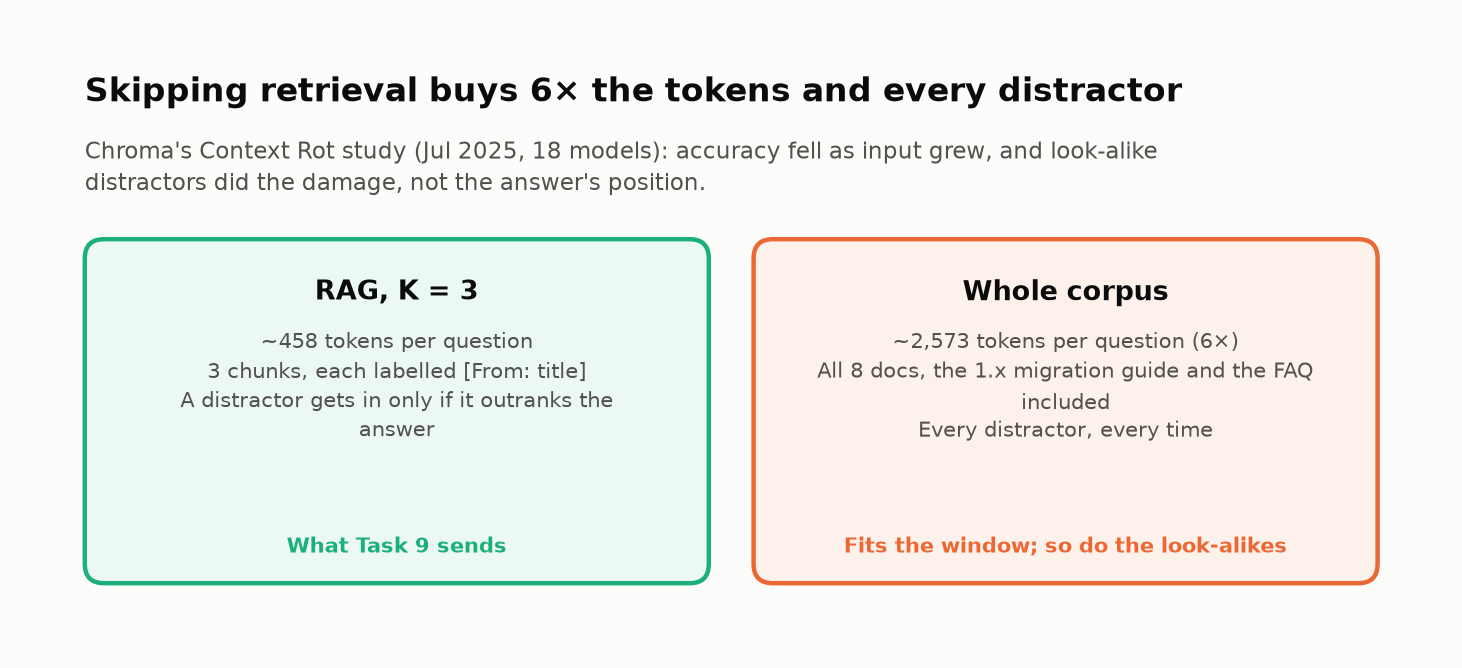
<sub>🖼️ *A corpus that fits the window still shouldn't go in it: everything beyond the 3 chunks is text the model must learn to ignore.*</sub>

🗣️ **Say it to a colleague:** "A bigger context window buys more distractors, not more answer."

✋ **Your turn:** steer the mock to the answer line.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_example_question = "How do I retry a task 3 times and wait 60s between retries?"   # one that works

In [ ]:
# ✋ Your turn: write a retry question whose mock answer contains `retries=3`.
#    Same pipeline, same index, same docs: only your wording changes.
my_question = ...   # ✏️ a question, in quotes

my_answer = "" if todo(my_question) else rag_pipeline(my_question).answer
if my_answer: print("Answer:", my_answer)
check("Steer the mock to retries=3", my_question, ok="retries=3" in my_answer,
      hint="The mock copies the context sentences that share the most words with your question. Which words does the @task(...) line itself use?",
      success="Your words changed the answer; the facts in the context did not. A generator that picks what sounds like the question is what Task 10's metrics have to grade.");

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** Tiles: **~458** vs **~2,573** tokens (6×).
</details>

In [ ]:
# @title ❓ Quick check: this corpus fits in any context window. Why still retrieve?
answer = "— pick one —"  # @param ["— pick one —", "A) Only cost: quality is the same with the whole corpus", "B) Models cannot read 2,600 tokens", "C) The position of the answer in a long prompt decides accuracy", "D) Cost and quality: the extra text is distractors, and accuracy falls as input grows"]
quiz('Why still retrieve', answer, correct="D",
     why="Context Rot (Chroma, 2025): every model scored higher with a focused ~300-token prompt than with the full ~113k, and look-alike distractors did the damage.",
     wrong={"A": 'Context Rot measured the opposite: accuracy fell as input grew, even on trivial tasks.',
          "B": 'Current models read far more. Can read is not the same as reads well.',
          "C": "Context Rot found the needle's position had no notable effect; distractors did."});

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Retrieval isn't only a cost trick: every extra chunk is a distractor the model must ignore.</b></font>

</td></tr></table>

---

## Task 10: Evaluate Generation Quality (RAGAS-style metrics) 📈

<big><b>Grounded is not correct.</b></big>

> 🎯 **Goal:** score **faithfulness** and **relevancy** next to answer found, per question.<br>
> ❓ **The question:** what can faithfulness see?<br>
> 👀 **Watch for:** a question whose evidence was never retrieved.

An **abstention** is counted apart: a right call, or an **over-refusal** if the evidence was there.

> 📘 **Concept · Faithfulness (groundedness)**
>
> **What it is:** the share of an answer's claims that the retrieved context supports. RAGAS extracts claims with an LLM and checks each; this lab's proxy counts the answer's content words that also appear in the context.
>
> **What it can't tell you:** whether the context held the answer, or whether the answer is right. It is **reference-free**: it never looks at the ground truth.
>
> **Anchor:** the mock generator only copies context sentences, so its faithfulness is near 1.0 by construction, whatever was retrieved.

In [ ]:
# @title 🔮 Predict: with the mock, faithfulness on a question whose evidence was NOT retrieved will be…
faithfulness_on_a_miss = "— pick one —"  # @param ["— pick one —", "A) near 0", "B) about 0.5", "C) near 1.0"]
print("🔮 Locked in. Graded after the reveal.")

▶️ **Run:** the faithfulness proxy → 👀 it counts shared words.

In [ ]:
# ============================================================
# GENERATION QUALITY METRICS: word-overlap proxies for two RAGAS metrics (RAGAS itself uses an LLM judge)
# ============================================================
def evaluate_faithfulness(answer: str, context: str) -> float:
    """Share of the answer's content words that appear in the context (0-1).
    RAGAS instead has an LLM extract each claim and verify it against the context."""
    stop_words = {'the', 'a', 'an', 'is', 'are', 'was', 'were', 'be', 'been',
                  'to', 'of', 'and', 'or', 'in', 'on', 'at', 'for', 'with',
                  'that', 'this', 'it', 'you', 'can', 'will', 'your'}
    answer_words = set(answer.lower().split()) - stop_words
    context_words = set(context.lower().split()) - stop_words
    if not answer_words:
        return 1.0
    # 👀 Look at: it counts shared WORDS. Copying the wrong paragraph scores 1.0; so does rearranging the right one.
    return min(len(answer_words & context_words) / len(answer_words), 1.0)

▶️ **Run** (code hidden): the relevancy proxy.

In [ ]:
# @title 🧰 Answer-relevancy proxy: 0.5 + 0.5 × share of question words reused (0.3 for a refusal, 0.4 under 5 words) (hidden · 39 lines · expand if curious)
def evaluate_answer_relevancy(
    question: str,
    answer: str
) -> float:
    """0.5 + 0.5 x share of the question's content words reused in the answer (0.3 for a refusal,
    0.4 for answers under 5 words). RAGAS instead generates questions from the answer
    and measures their similarity to the original question."""
    # Check for refusal/uncertainty
    refusal_phrases = ["don't have", "cannot", "no information", "not sure"]
    answer_lower = answer.lower()
    
    if any(phrase in answer_lower for phrase in refusal_phrases):
        return 0.3  # Refusal is somewhat relevant (honest)
    
    # Very short answers are likely low relevancy
    if len(answer.split()) < 5:
        return 0.4
    
    # Check term overlap
    question_words = set(question.lower().split())
    answer_words = set(answer.lower().split())
    
    stop_words = {'the', 'a', 'an', 'is', 'are', 'how', 'what', 'do', 'does',
                  'to', 'of', 'and', 'or', 'in', 'on', 'at', 'for', 'with', 'i', 'my'}
    
    question_words = question_words - stop_words
    answer_words = answer_words - stop_words
    
    if not question_words:
        return 0.5
    
    overlap = question_words & answer_words
    relevancy = len(overlap) / len(question_words)
    
    # Scale to reasonable range
    return min(0.5 + relevancy * 0.5, 1.0)


print("✅ Generation evaluation functions defined")

▶️ **Run:** the full pipeline on 14 questions.

In [ ]:
# ============================================================
# FULL RAG EVALUATION: retrieval + generation, per question
# ============================================================
def evaluate_rag_pipeline(evaluation_dataset, top_k=K_CONTEXT):
    rows = []
    for item in evaluation_dataset:
        resp = rag_pipeline(item["question"], top_k)
        ids = [r.doc_id for r in resp.retrieved_chunks]
        # 👀 Look at: an abstention makes no claims, so it is counted apart, never scored as 'unfaithful'
        abstained = "don't have enough information" in resp.answer.lower()
        rows.append({
            "question": item["question"][:44], "style": item["style"],
            "recall@k": compute_recall_at_k(ids, item["relevant_doc_ids"], top_k),
            "answer_found": answer_found(resp.retrieved_chunks, item["evidence_spans"]),
            # An abstention makes no claims, so faithfulness/relevancy don't apply: score it separately (NaN here)
            "faithfulness": np.nan if abstained else evaluate_faithfulness(resp.answer, resp.context_used),
            "relevancy": np.nan if abstained else evaluate_answer_relevancy(item["question"], resp.answer),
            "abstained": abstained,
            "answer": resp.answer[:90],
        })
    return pd.DataFrame(rows)

print(f"Running the full pipeline ({FINAL_STACK}, K = {K_CONTEXT}, generator = {PROVIDER})...")
full_eval = evaluate_rag_pipeline(EVALUATION_DATASET)
print("✅ Evaluation complete!")

▶️ **Run:** one row per question, then tiles → read *Answered without evidence*.

In [ ]:
# ============================================================
# DISPLAY RESULTS: generation metrics next to retrieval, per question
# ============================================================
print(full_eval[["question", "answer_found", "faithfulness", "relevancy", "abstained"]].to_string(index=False, float_format="%.2f", na_rep="—"))

found, abst = full_eval["answer_found"] == 1, full_eval["abstained"]
qnum = lambda mask: [i + 1 for i in full_eval.index[mask]]          # 1-based question numbers
# 👀 Look at: the cell no generation metric scores: evidence missing, answer given
confident_miss = qnum(~found & ~abst)    # evidence NOT retrieved, answered anyway
over_refusal = qnum(found & abst)        # evidence retrieved, refused anyway
good_abstain = qnum(~found & abst)       # evidence not retrieved, abstained
answered = full_eval[~abst]
tiles([
    ("Answer found (retrieval)", f"{found.mean():.0%}", f"n = {len(full_eval)}", None),
    ("Faithfulness (answered)", f"{answered['faithfulness'].mean():.2f}", f"generator = {PROVIDER}", "warning" if PROVIDER == "mock" else None),
    ("Relevancy (answered)", f"{answered['relevancy'].mean():.2f}", "word-overlap proxy", None),
    ("Answered without evidence", len(confident_miss), f"questions {confident_miss}", "critical" if confident_miss else "good"),
    ("Refused despite evidence", len(over_refusal), f"questions {over_refusal}", "warning" if over_refusal else "good"),
])

✋ **Your turn:** place three questions in the outcome grid.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_row = lambda q: full_eval.iloc[q - 1]
_ref_labels = {q: ("confident miss" if (_row(q)["answer_found"] == 0 and not _row(q)["abstained"]) else
                   "right call" if (_row(q)["answer_found"] == 0 and _row(q)["abstained"]) else
                   "over-refusal" if _row(q)["abstained"] else "graded") for q in (7, 13, 14)}

In [ ]:
# ✋ Your turn: label each question "confident miss" (no evidence, answered anyway), "right call" (no evidence,
#    abstained) or "over-refusal" (evidence retrieved, abstained). Read answer_found and abstained above.
my_labels = {7: ..., 13: ..., 14: ...}   # ✏️ replace each ... with a label, in quotes

_got = ... if any(todo(v) for v in my_labels.values()) else {q: str(v).strip().lower() for q, v in my_labels.items()}
check("Three outcomes faithfulness can't see", _got, _ref_labels,
      hint="Two columns decide it: was the evidence retrieved (answer_found = 1)? Did the pipeline abstain?",
      success=f"Faithfulness scores only the {int((~full_eval['abstained']).sum()) - len(confident_miss)} graded answers. Q7 answered without its evidence, Q13 abstained correctly, Q14 refused with the evidence in hand: each needs its own number.");

▶️ **Run:** two cards, then grades your prediction.

In [ ]:
# ── Reveal: what faithfulness can and can't see ──
cm_faith = full_eval.loc[[q - 1 for q in confident_miss], "faithfulness"]
insight(
    (f"Faithfulness on answered questions is {answered['faithfulness'].mean():.2f}, and {cm_faith.mean():.2f} on question(s) "
     f"{confident_miss}, where the answer never reached the generator") if confident_miss else
    f"Faithfulness on answered questions is {answered['faithfulness'].mean():.2f}",
    ("The mock generator copies sentences from the context, so it is faithful by construction, even when the context "
     "doesn't contain the answer: a faithful answer to the wrong chunk is still a wrong answer. "
     if PROVIDER == "mock" else
     f"These are {OPENAI_MODEL}'s answers. Compare them with the mock run: where does faithfulness drop? ")
    + (f"It abstained on {good_abstain} (right call: the evidence wasn't retrieved) " if good_abstain else "")
    + (f"and refused {over_refusal} even though the evidence *was* there (a vocabulary mismatch, the over-refusal "
       "pattern from Lab 04). " if over_refusal else "")
    + "\n**Rule of thumb:** read generation metrics next to retrieval metrics, per question, and score abstentions "
    "separately. *Answer not found + confident answer* should trigger abstention, not a pass.",
    kind="warning")
insight(
    "Google's *Sufficient Context* study: retrieval can make a model *less* likely to abstain",
    "Joren et al. (ICLR 2025) labeled whether the retrieved context could answer each question at all. Large models (Gemini 1.5 "
    "Pro, GPT-4o, Claude 3.5) \"often output incorrect answers instead of abstaining\" when it couldn't, and adding retrieved "
    "context can make a model less likely to abstain: any context looks like permission to answer. "
    + (f"Question(s) {confident_miss} sit in exactly that cell: evidence missing, answer given.\n" if confident_miss else "\n")
    + "**Rule of thumb:** label context sufficiency per test case and report *answered without sufficient context* as its own failure rate.",
    kind="research")

_miss_faith = cm_faith.mean() if len(cm_faith) else answered["faithfulness"].mean()
quiz("Your prediction: faithfulness on a miss", faithfulness_on_a_miss,
     correct="A" if _miss_faith < 0.3 else "B" if _miss_faith < 0.7 else "C",
     why=f"{_miss_faith:.2f} on question(s) {confident_miss}: every word the mock says comes from the context, answer or not.");

🔍 **What just happened:** the mock only copies context, so faithfulness is ~1.0 whether or not the context held the answer.

<!-- img: answer-quadrant.png -->
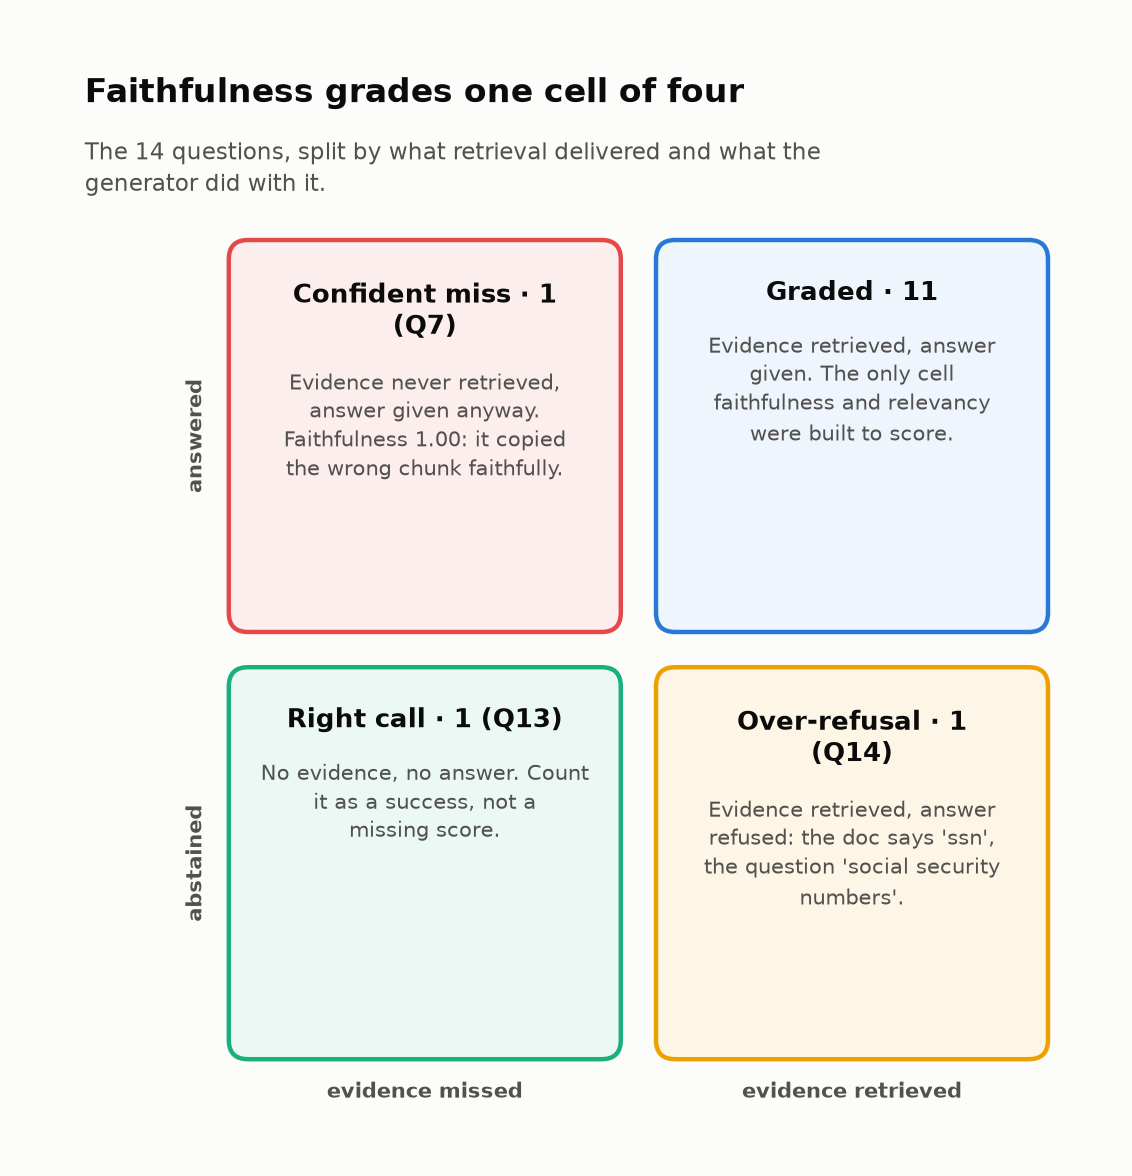
<sub>🖼️ *Three of the four outcomes are invisible to faithfulness. Report each cell as its own number.*</sub>

🗣️ **Say it to a colleague:** "Faithfulness asks whether the answer copied the context, not whether the context held the answer."

🎛️ **Try it:** ask something the docs can't answer. Does the mock abstain? What does faithfulness say?

In [ ]:
MY_QUESTION = "Does BrookPipe support Snowflake?"  # @param {type:"string"}
r = rag_pipeline(MY_QUESTION)
abstained = "don't have enough information" in r.answer.lower()
print(f"Answer: {r.answer}\nabstained: {abstained} · faithfulness proxy: {evaluate_faithfulness(r.answer, r.context_used):.2f}")

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** answer found **86%** · faithfulness **0.96** · relevancy **0.67** · confident miss **[7]** · over-refusal **[14]**.
</details>

In [ ]:
# @title ❓ Quick check: faithfulness is 0.96 on answered questions. What does that tell you?
answer = "— pick one —"  # @param ["— pick one —", "A) The answers reuse the context's words; nothing about whether the context held the answer", "B) 96% of the answers are correct", "C) Retrieval found the evidence 96% of the time"]
quiz('What 0.96 faithfulness means', answer, correct="A",
     why="It is reference-free: it never looks at the ground truth or at whether the evidence arrived. Question 7 scored 1.00 with no evidence.",
     wrong={"B": 'Correctness needs a reference. 🏆 Challenge 4 finds key-fact accuracy far below 96%.',
          "C": 'That is answer found, a retrieval metric: 86% here.'});

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Read generation metrics next to retrieval, per question, and count abstentions as their own outcomes.</b></font>

</td></tr></table>

---

## Task 11: Production Readiness Assessment 🎯

<big><b>A verdict without thresholds written in advance is an opinion.</b></big>

> 🎯 **Goal:** apply thresholds written in advance.<br>
> ❓ **The question:** how wide is the margin?<br>
> 👀 **Watch for:** the metric closest to its minimum.

Thresholds are a **product decision**.

In [ ]:
# @title 🔮 Predict: with these thresholds and a mock generator, the verdict will be…
ship_call_will_be = "— pick one —"  # @param ["— pick one —", "A) SHIP", "B) SHIP WITH CAUTION", "C) BLOCK"]
print("🔮 Locked in. Graded after the reveal.")

▶️ **Run:** thresholds (min · target) and one tile per metric.

In [ ]:
# ============================================================
# PRODUCTION READINESS CHECK → VERDICT
# ============================================================
# Generation metrics are averaged over ANSWERED questions; abstentions are reported on their own line.
THRESHOLDS = {   # written down BEFORE looking at results (a product decision, not a law of nature)
    "answer_found": {"min": 0.80, "target": 0.90},
    "faithfulness": {"min": 0.75, "target": 0.90},
    "relevancy":    {"min": 0.65, "target": 0.80},
}

def assess_readiness(eval_df, thresholds):
    out = {}
    for metric, b in thresholds.items():
        v = eval_df[metric].mean()
        out[metric] = (v, "good" if v >= b["target"] else "warning" if v >= b["min"] else "critical")
    return out

readiness = assess_readiness(full_eval, THRESHOLDS)
tiles([(m, f"{v:.2f}", f"min {THRESHOLDS[m]['min']:.2f} · target {THRESHOLDS[m]['target']:.2f}", s)
       for m, (v, s) in readiness.items()])

✋ **Your turn:** apply the written rule before the code does.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
blockers = [m for m, (v, s) in readiness.items() if s == "critical"]
warnings = [m for m, (v, s) in readiness.items() if s == "warning"]
decision = "BLOCK" if blockers else ("SHIP WITH CAUTION" if warnings or PROVIDER == "mock" else "SHIP")
_n_q, _found_q = len(full_eval), int(full_eval["answer_found"].sum())
_ref_misses = next(m for m in range(1, _n_q + 1) if (_found_q - m) / _n_q < THRESHOLDS["answer_found"]["min"])

In [ ]:
# ✋ Your turn: the rule, written before the results: any metric below its minimum → "BLOCK";
#    otherwise any metric below target, or a mock generator → "SHIP WITH CAUTION"; otherwise "SHIP".
my_call = ...   # ✏️ "SHIP", "SHIP WITH CAUTION" or "BLOCK", from the tiles above

check("The ship call", my_call, decision,
      hint="Read each tile against its minimum first, then its target. PROVIDER is still 'mock'.",
      success=f"{decision}: nothing is below a minimum, {len(warnings)} metric(s) below target, and the generator is a mock.");

✋ **Your turn:** now the margin.

In [ ]:
# ✋ Your turn: how close is BLOCK? Answer found is `found` of `n` questions against a minimum of 0.80.
n, found = len(full_eval), int(full_eval["answer_found"].sum())
print(f"answer found: {found} of {n} = {found / n:.0%}")

my_misses = ...   # ✏️ how many MORE retrieval misses turn the verdict into BLOCK?

check("Misses until BLOCK", my_misses, _ref_misses,
      hint="Try found − 1, found − 2, …: when does (found − m) / n drop below 0.80?",
      success=f"{_ref_misses}: at {found - _ref_misses} of {n}, answer found reads {(found - _ref_misses) / n:.0%} and the same rule says BLOCK. One question decides this verdict.");

▶️ **Run:** the verdict with its reasons, then grades your prediction.

In [ ]:
# ── Decide: the rule (blockers, warnings, decision) ran in the hidden answer-key cell above ──
# 👀 Look at: the rule was written before the results; the code only applies it
af = full_eval["answer_found"]
verdict(decision, [
    f"**Retrieval:** {FINAL_STACK} on '{BEST_CONFIG}' chunks finds the answer {af.mean():.0%} of the time at K = {K_CONTEXT} "
    f"(n = {len(af)}; one question = {1 / len(af):.0%})." + (f" Below minimum: {', '.join(blockers)}." if blockers else ""),
    f"**Chunking:** chosen by evidence-level metrics; the 800/400 default would send "
    f"{sweep_df.loc['fixed 800 / 400 overlap', 'tokens_sent'] / sweep_df.loc[BEST_CONFIG, 'tokens_sent']:.1f}× the tokens.",
    ("**Generation is unproven:** the mock generator is extractive, so faithfulness "
     f"{readiness['faithfulness'][0]:.2f} measures the mock, not a model. Re-run with PROVIDER='openai' before deciding."
     if PROVIDER == "mock" else f"**Generation:** {OPENAI_MODEL} scored faithfulness {readiness['faithfulness'][0]:.2f}."),
    f"**Abstention:** declined {int(full_eval['abstained'].sum())} of {len(full_eval)} questions "
    f"({len(over_refusal)} despite retrieved evidence: {over_refusal}); answered {len(confident_miss)} without the evidence: {confident_miss}.",
    f"**Below target:** {', '.join(warnings) or 'none'}. The word-overlap relevancy proxy is crude; confirm with an LLM judge "
    "validated against human labels (Module 05) before treating it as a blocker.",
    "**Before shipping:** grow the eval set from real user queries, add unanswerable questions to test abstention "
    "(Lab 04, Task 9), and keep the 1.x migration guide out of answers about 2.0.",
])

quiz("Your prediction: the ship call", ship_call_will_be, correct={"SHIP": "A", "SHIP WITH CAUTION": "B", "BLOCK": "C"}[decision],
     why=f"{decision}: answer found {af.mean():.0%} clears its 0.80 minimum by one question, and the mock caps any verdict at caution.");

🔍 **What just happened:** <mark>one retrieval miss turns this verdict into BLOCK</mark>, and the mock caps it at caution anyway.

<!-- img: rag-review-steps.png -->
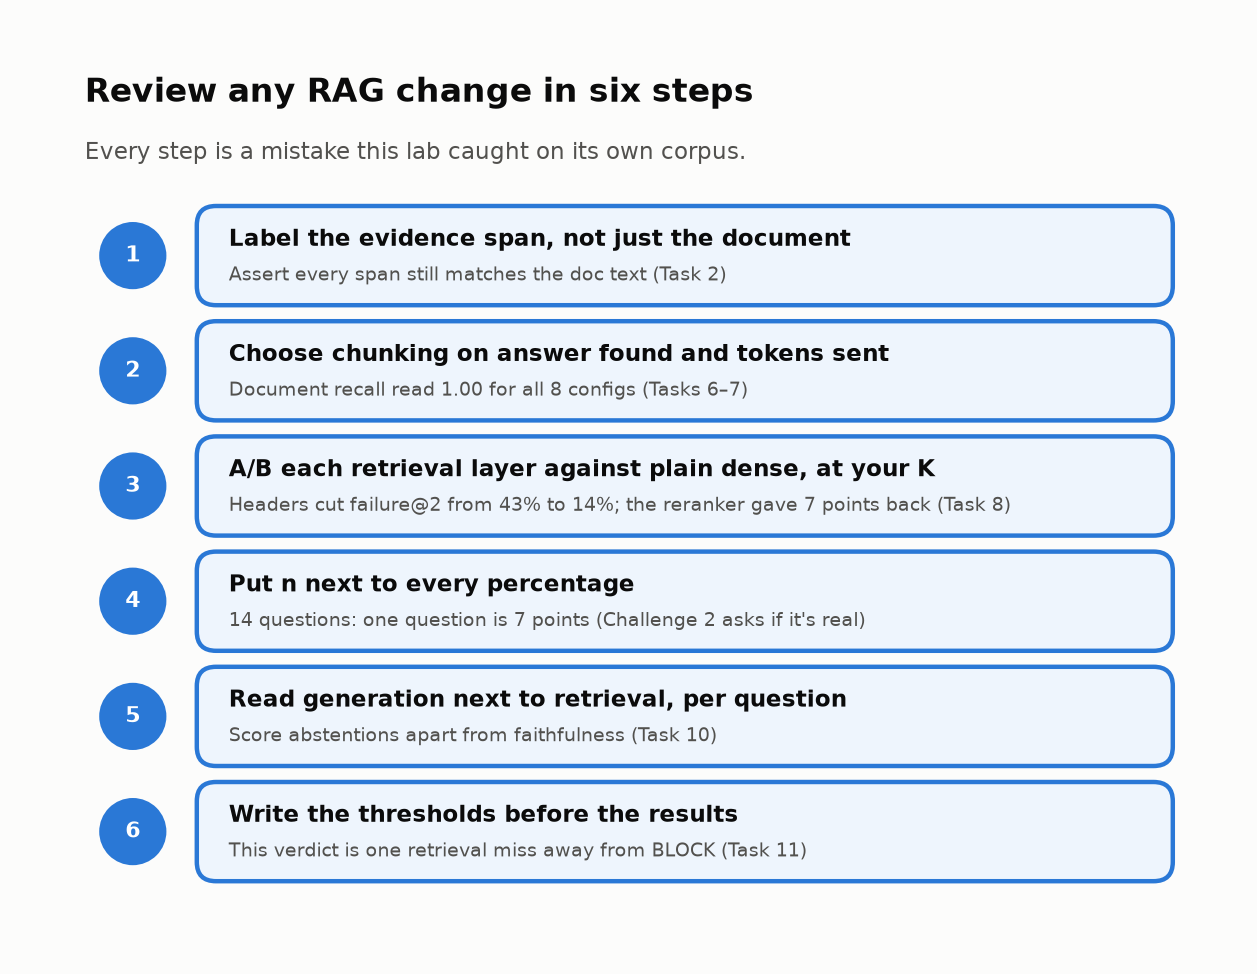
<sub>🖼️ *The lab as a checklist: each step is a mistake this corpus caught. Pin it next to your next RAG design review.*</sub>

In [ ]:
# @title ❓ Quick check: relevancy reads 0.67 against a minimum of 0.65, from a crude word-overlap proxy. What do you do?
answer = "— pick one —"  # @param ["— pick one —", "A) Lower the minimum to 0.60, so it is safely green", "B) Ignore relevancy: it is only a proxy", "C) Keep the threshold and validate the proxy against human labels before it gates anything"]
quiz('A gauge at its minimum', answer, correct="C",
     why="A crude gauge next to a hard threshold is a coin toss: with the cross-encoder it reads 0.647 and the verdict flips to BLOCK. Validate the gauge; do not move the line.",
     wrong={"A": 'Moving the goalposts after seeing results is what writing thresholds first prevents.',
          "B": "A crude gauge still carries signal. Validate it; don't delete it."});

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Write thresholds before the results and put n next to every percentage.</b></font>

</td></tr></table>

---

## ✅ Validation / Success Criteria

<details><summary>Check yourself</summary>

- [ ] You can say why Recall@5 tied and answer found didn't
- [ ] `scoreboard()` is green, or you know why not
</details>

## 🛠️ Troubleshooting

<details><summary>Common problems</summary>

| Symptom | Fix |
|---|---|
| `NameError` | **Runtime → Run all** |
| `Could not load MiniLM` | Offline fallback; numbers differ |
| `openai.NotFoundError` | Change `OPENAI_MODEL` |
</details>

## 🚀 Stretch Goal / Extension

`PROVIDER = "openai"`, `RERANKER = "cross-encoder"`, or RAGAS 0.4 as the faithfulness judge.

### 🏆 Challenge exercises

🧭 **Where you are:** each challenge attacks a number the verdict rests on.

#### 🌶️ Challenge 1: Break the metric
**Stakes:** a dashboard showing Recall@K = 1.00 will approve a retriever that hands the model the right manual, open at the wrong page.

Pick chunks for question 4 with **Recall@K = Precision@K = 1.00, answer found = 0**.

<details><summary>💡 Hint</summary>

Precision@K only asks whether each chunk comes from a relevant *document*. The evidence sits at chars 171–238 of doc-004. Which doc-004 chunks don't overlap it?
</details>

In [ ]:
# ── 🌶️ Challenge 1: a perfect Recall@K that delivers nothing ──
q1 = EVALUATION_DATASET[3]                                   # "How do I configure retries for failed tasks?"
CHUNK_POOL = {c.id: c for c in prod_chunks}                  # the 'recursive 200' chunks behind your pipeline
print("doc-004 chunks:", [(cid, c.start_char, c.end_char) for cid, c in CHUNK_POOL.items() if c.doc_id == "doc-004"],
      "· evidence span:", q1["evidence_spans"])

# TODO: list chunk ids (any K ≥ 1) so that Recall@K = 1.0 and Precision@K = 1.0, yet answer found = 0
MY_CHUNK_IDS = []

my_results = [RetrievalResult(c.id, c.content, c.doc_id, c.doc_title, c.start_char, c.end_char, 1.0)
              for cid in MY_CHUNK_IDS if (c := CHUNK_POOL.get(cid))]
if not my_results:
    print("❌ Not yet: put at least one chunk id in MY_CHUNK_IDS")
else:
    _ids, _k = [r.doc_id for r in my_results], len(my_results)
    _rec = compute_recall_at_k(_ids, q1["relevant_doc_ids"], _k)
    _prec = compute_precision_at_k(_ids, q1["relevant_doc_ids"], _k)
    _ev = evidence_metrics(my_results, q1["evidence_spans"])
    print(f"K = {_k} · Recall@K = {_rec:.2f} · Precision@K = {_prec:.2f} · evidence recall = {_ev['ev_recall']:.2f} "
          f"· IoU = {_ev['iou']:.3f}")
    print("✅ Metric broken: perfect document scores, zero answer." if _rec == 1 and _prec == 1 and _ev["ev_recall"] < 0.5
          else "❌ Not yet: you need Recall = Precision = 1.00 with evidence recall below 0.50")


#### 🌶️🌶️ Challenge 2: Is the staircase real?
**Stakes:** a "67% fewer failures" slide built on 14 questions can fund a quarter's work on noise.

Only *discordant* questions count, each a coin flip if the stacks are equal (exact **McNemar**). Keep headers? Drop the reranker?

<details><summary>💡 Hint</summary>

Two-sided exact p = min(1, 2 × Σ C(m, i) / 2ᵐ for i = 0 … min(a_only, b_only)), where m = a_only + b_only. With 6 discordant questions split 1 : 5, p = 2 × (1 + 6) / 64.
</details>

In [ ]:
# ── 🌶️🌶️ Challenge 2: is the staircase real, or is it 14 coin flips? ──
from math import comb

def found_vector(stack):
    """Per-question 1/0: did this stack get the answer into the top 2? (same 14 questions, same order)"""
    return stack_detail[stack]["answer_found"].astype(int).tolist()

def exact_mcnemar_p(a, b):
    """Two-sided exact McNemar test for paired 0/1 outcomes on the SAME questions.
    Only discordant questions (one stack found the answer, the other didn't) carry information."""
    # TODO 1: a_only = questions a found and b missed; b_only = the reverse
    # TODO 2: under H0 each discordant question is a fair coin: p = min(1, 2 * P(X <= min(a_only, b_only))), X ~ Bin(n, 0.5)
    return None

def questions_needed(a_only=1, b_only=5, alpha=0.05):
    """If the discordant questions keep their split (a_only : b_only) and their share of the eval set
    (6 of 14), how many questions until the difference is significant? Return the smallest n."""
    # TODO 3: scale the discordant counts with n, call your test, return the first n with p < alpha
    return None

_pairs = [("dense", "hybrid + context headers"), ("hybrid + context headers", "hybrid + headers + rerank")]
for (_a, _b), _want in zip(_pairs, (0.21875, 1.0)):
    _p = exact_mcnemar_p(found_vector(_a), found_vector(_b))
    print(f"{_a:>26} vs {_b:<26} p = {_p if _p is None else round(_p, 3)}  "
          + ("✅" if _p is not None and abs(_p - _want) < 1e-6 else "❌ (TODO 1–2)"))
_n = questions_needed()
print(f"questions needed: {_n}  " + ("✅" if _n == 27 else "❌ (TODO 3; hint: it's more than 14)"))


#### 🌶️🌶️🌶️ Challenge 3: Last year's page wins
**Stakes:** in a tax assistant the most dangerous distractor is last year's rule: same topic, same words, wrong year. Simulate it on BrookPipe.

**Attack:** a legacy page that puts `max_retries` in question 4's answer. **Defend:** a metadata-only `version_guard` that keeps answer found.

<details><summary>💡 Hint</summary>

The mock generator copies the two context sentences that share the most words with the question; BM25 rewards exact word overlap and dense rewards similar meaning. A page that restates the question's own words wins all three. For the guard: which categories should never answer a 2.0 question unless the user mentions upgrading?
</details>

In [ ]:
# ── 🌶️🌶️🌶️ Challenge 3: last year's page outranks this year's answer ──
STALE_MARKERS = ["max_retries"]                              # 1.x-only syntax: it must never reach a 2.0 answer
q3 = EVALUATION_DATASET[3]                                   # "How do I configure retries for failed tasks?"

# TODO 1 (attack): write a legacy 1.x page that wins retrieval for q3 and smuggles `max_retries` into the answer.
STALE_DOC = {"id": "doc-009", "title": "BrookPipe 1.x Notes", "category": "legacy",
             "content": "# BrookPipe 1.x Notes\n\nTODO: write the page that outranks the Error Handling guide."}

# TODO 2 (defense): drop chunks that should never answer a 2.0 question. You get the ranked results and the question.
def version_guard(question, results):
    return results

▶️ **Run** (code hidden): indexes your page, runs the stack with and without your guard, checks both.

In [ ]:
# @title 🧰 Challenge 3 harness: indexes your page next to the real docs, runs the shipped stack with and without your guard, checks both (hidden · 28 lines · expand if curious)
def attack_index(extra_docs):
    for d in extra_docs:
        DOC_TEXT[d["id"]] = d["content"].strip()             # register the doc so chunk offsets resolve
    ingest_chunks(SWEEP_CONFIGS[BEST_CONFIG]() + recursive_chunking(extra_docs, 200), "AttackCtx", contextual=True,
                  verbose=False)

DOC_META = {d["id"]: d for d in DOCUMENTS + [STALE_DOC]}     # what a real CMS gives you: id, title, category

def run_pipeline(question, guard):
    wide = retrieve(question, "AttackCtx", 10, "hybrid")      # same stack as FINAL_STACK, on the poisoned index
    top = (version_guard(question, wide) if guard else wide)[:K_CONTEXT]
    context = "\n\n---\n\n".join(f"[From: {r.doc_title}]\n{r.content}" for r in top)
    return top, generate_answer(question, context)

attack_index([STALE_DOC])
_top, _ans = run_pipeline(q3["question"], guard=False)
_stale = any(m in _ans for m in STALE_MARKERS)
print(f"Unguarded top-{K_CONTEXT}: {[r.doc_id for r in _top]}\nAnswer: {_ans[:110]}")
print("✅ Attack works: the stale syntax reached the answer" if _stale else "❌ Attack not yet: no stale marker in the answer")

_gtop, _gans = run_pipeline(q3["question"], guard=True)
_found = lambda guard: np.mean([answer_found(run_pipeline(it["question"], guard)[0], it["evidence_spans"])
                                for it in EVALUATION_DATASET])
_af_off, _af_on = _found(False), _found(True)
print(f"Guarded answer: {_gans[:110]}\nAnswer found over 14 questions: unguarded {_af_off:.0%} · guarded {_af_on:.0%}")
print("✅ Defense works: no stale answer, and no answer lost" if _stale and not any(m in _gans for m in STALE_MARKERS)
      and _af_on >= _af_off else "❌ Defense not yet (needs a working attack first, and must not lower answer found)")


#### 🌶️🌶️ Challenge 4: Green on every gauge, wrong answer
**Stakes:** in a payroll help bot, an answer can be retrieved, grounded and on-topic and still quote the wrong sentence of the right policy, and none of Task 11's gauges compares the answer with what a correct one says.

Add a **reference-based** check (`KEY_FACTS`) and find answers green on all three gauges but wrong.

<details><summary>💡 Hint</summary>

`gauges` is Task 10's `full_eval` plus `q` (question number, 1–14) and `full_answer` (untruncated). A row is green when `gauges[m] >= THRESHOLDS[m]["min"]` for `answer_found`, `faithfulness` and `relevancy`; abstentions have NaN scores, and NaN ≥ anything is False. Count before you read: how many answered questions does your `answer_correct` call right?
</details>

In [ ]:
# ── 🌶️🌶️ Challenge 4: three green gauges, one wrong answer ──
KEY_FACTS = {   # question number → strings a correct answer must contain (written from ground_truth_answer)
    1: ["pip install brookpipe"], 2: ["./brookpipe.yaml"], 3: ["duration"], 4: ["retries=3"],
    5: ["api key", "oauth", "saml"], 6: ["in parallel"], 7: ["environment variable"], 8: ["directed acyclic graph"],
    9: ["run.status"], 10: ["postgresql", "mysql"], 11: ["timeout"], 12: ["failed tasks"],
    13: ["circuit breaker"], 14: ["column-level encryption"],
}
gauges = full_eval.assign(q=range(1, len(full_eval) + 1),   # re-runs the pipeline for untruncated answers
                          full_answer=[rag_pipeline(it["question"]).answer for it in EVALUATION_DATASET])

# TODO 1: True only if `answer` contains EVERY string in `facts` (case-insensitive)
def answer_correct(answer, facts):
    return None

# TODO 2: question numbers that clear all three Task 11 minimums (answer_found, faithfulness, relevancy)
#         and still fail answer_correct
def green_but_wrong(gauges, thresholds=THRESHOLDS):
    return []

▶️ **Run** (code hidden): the checker (it holds the answers: try first).

In [ ]:
# @title 🧰 Challenge 4 checker: reference versions of both TODOs, tiles, ✅/❌ (hidden · 32 lines · it's the answer, so expand only after you've tried)
def _ref_correct(answer, facts):
    return all(f.lower() in answer.lower() for f in facts)

def _ref_green_but_wrong(g, thresholds=THRESHOLDS):
    green = np.ones(len(g), dtype=bool)
    for m in ("answer_found", "faithfulness", "relevancy"):
        green &= (g[m] >= thresholds[m]["min"]).to_numpy()
    return [int(r.q) for r, ok in zip(g.itertuples(), green) if ok and not _ref_correct(r.full_answer, KEY_FACTS[r.q])]

_mine = [answer_correct(r.full_answer, KEY_FACTS[r.q]) for r in gauges.itertuples()]
_ref = [_ref_correct(r.full_answer, KEY_FACTS[r.q]) for r in gauges.itertuples()]
_unit = (answer_correct("Run PIP INSTALL BrookPipe", ["pip install brookpipe"]) is True
         and answer_correct("OAuth 2.0 only", ["oauth", "saml"]) is False)
_ok1 = _unit and [bool(x) for x in _mine] == _ref and None not in _mine
_gbw = sorted(int(q) for q in green_but_wrong(gauges))
_ok2 = _ok1 and _gbw == _ref_green_but_wrong(gauges)
_answered = gauges[~gauges["abstained"]]
tiles([
    ("Answer found", f"{gauges['answer_found'].mean():.0%}", f"n = {len(gauges)}", None),
    ("Faithfulness (answered)", f"{_answered['faithfulness'].mean():.2f}", "reference-free", None),
    ("Key-fact accuracy", f"{np.mean([bool(x) for x in _mine]):.0%}" if _ok1 else "?", "your answer_correct()",
     ("critical" if np.mean(_ref) < 0.8 else "good") if _ok1 else None),
    ("Green but wrong", len(_gbw) if _ok2 else "?", f"questions {_gbw}" if _ok2 else "your green_but_wrong()",
     ("critical" if _gbw else "good") if _ok2 else None),
])
print("TODO 1 answer_correct:", "✅" if _ok1 else "❌ (True only when every fact appears, in any case)")
print("TODO 2 green_but_wrong:", "✅" if _ok2 else f"❌ (you returned {_gbw}; needs TODO 1 first)")
if _ok2:
    for q in _gbw:
        r = gauges.loc[gauges["q"] == q].iloc[0]
        print(f"   Q{q} · faithfulness {r['faithfulness']:.2f} · relevancy {r['relevancy']:.2f} · needs {KEY_FACTS[q]}\n"
              f"        → {r['full_answer'][:105]}")

#### 🌶️🌶️🌶️ Challenge 5: A faithful lie
**Stakes:** a tax assistant that tells a W-2 employee they *can* deduct a home office invites a wrong return, and Task 10's faithfulness proxy can rate that answer 1.00.

Shared words aren't **entailment**. **Attack:** a `LIE` scoring ≥ 0.95. **Defend:** a `strict_faithfulness` that sinks it.

<details><summary>💡 Hint</summary>

Attack: read `evaluate_faithfulness` in Task 10. Which words does it throw away, and what does `split()` do with the full stop at the end of a sentence? Defense: pair each answer sentence with the context sentence it shares the most words with, then ask which single word could make the two say opposite things.
</details>

In [ ]:
# ── 🌶️🌶️🌶️ Challenge 5: a lie built from the context's own words ──
TAX_CONTEXT = """[From: Fernleaf Tax Help > Home office]
Self-employed filers can deduct home office costs when the space is used regularly and only for business.
Commuting costs between home and a regular workplace are never deductible.
W-2 employees cannot deduct home office costs on a federal return."""
QUESTION = "I'm a W-2 employee and I work from home. Can I deduct my home office?"
HONEST = "W-2 employees cannot deduct home office costs on a federal return."

# TODO 1 (attack): one sentence telling a W-2 employee they CAN deduct home office costs, scoring ≥ 0.95
LIE = ""

# TODO 2 (defense): sink lies made of the context's own words; keep honest, copied answers near 1.0
def strict_faithfulness(answer, context):
    return evaluate_faithfulness(answer, context)

▶️ **Run** (code hidden): the checker: your lie, a held-out lie, the honest answer, then one more lie.

In [ ]:
# @title 🧰 Challenge 5 checker: your lie, a held-out lie, the honest answer, the pipeline's real answers, then one more lie (hidden · 24 lines · expand after you've tried)
HELD_OUT_LIE = "Commuting costs between home and a regular workplace are deductible."
_NEG = re.compile(r"\b(not|never|cannot|no|none)\b|n't\b", re.I)
_lie_proxy = evaluate_faithfulness(LIE, TAX_CONTEXT) if LIE.strip() else 0.0
_lie_ok = (_lie_proxy >= 0.95 and "w-2" in LIE.lower() and "deduct" in LIE.lower() and not _NEG.search(LIE))
print(f"Attack · proxy faithfulness of your lie: {_lie_proxy:.2f}  "
      + ("✅ a lie the proxy rates as faithful" if _lie_ok else "❌ (needs ≥ 0.95, must mention W-2 and deduct, no not/never/cannot)"))

_real = [(r.answer, r.context_used) for r in (rag_pipeline(it["question"]) for it in EVALUATION_DATASET)
         if "don't have enough information" not in r.answer.lower()]
_s = lambda a, c=TAX_CONTEXT: float(strict_faithfulness(a, c))
_scores = {"your lie": _s(LIE) if LIE.strip() else float("nan"), "held-out lie": _s(HELD_OUT_LIE),
           "honest answer": _s(HONEST), f"{len(_real)} real answers (mean)": float(np.mean([_s(a, c) for a, c in _real]))}
for _k, _v in _scores.items():
    print(f"   strict · {_k:<26} {_v:.2f}")
_v = list(_scores.values())
_def_ok = _lie_ok and _v[0] < 0.5 and _v[1] < 0.5 and _v[2] >= 0.9 and _v[3] >= 0.9
print("Defense · " + ("✅ both lies sink, honest answers float" if _def_ok
                      else "❌ (lies < 0.5, honest ≥ 0.9, real answers ≥ 0.9 on average; needs a working attack first)"))
if _def_ok:
    _swap = "W-2 employees can deduct home office costs when the space is used regularly and only for business."
    _sv = _s(_swap)
    print(f"\nOne more lie: {_swap!r}\n   proxy {evaluate_faithfulness(_swap, TAX_CONTEXT):.2f} · strict {_sv:.2f}  "
          + ("⚠️ it passes your check: it borrows the self-employed rule and changes who it applies to." if _sv >= 0.5
             else "🏅 caught that too. Which lie gets past you next?"))

---

## 🏁 Key Takeaways

**🔑 The five things to remember**

1. **Evaluate the evidence, not the document.**
2. **Defaults are hypotheses:** test 800/400 and "always rerank".
3. **Retrievers fail differently:** fuse, add headers, A/B each layer at your K.
4. <font color="#2a78d6"><b>Reference-free gauges can all be green on a wrong answer.</b></font>
5. **Write thresholds first; put n next to every percentage.**

### 📒 Insight Ledger

| Task | What you saw | Rule of thumb |
|---|---|---|
| 6 · Two lenses | Recall@5 1.00 for both; answer found 93% vs 79% | Score evidence, not documents |
| 7 · Sweep | 800/400: worst IoU | Never trust a default |
| 8 · Stack | failure@2 43% → 14%; rerank +7 pts | A/B each layer |
| 9 · Generation | 6× fewer tokens than the whole corpus | Big windows don't retire retrieval |
| 10 · Quality | Faithfulness 1.00 on an unretrieved answer | Read generation next to retrieval |
| 11 · Verdict | ⚠️ CAUTION, one miss from BLOCK | Thresholds first |
| 🏆 4–5 | 4 green-but-wrong answers; a faithful lie | Keep a reference-based check |

▶️ **Run:** see which exercises and checks to revisit, then close the store.

In [ ]:
scoreboard()
store.close()   # stops embedded Weaviate; a no-op for the in-memory store